# The construction's weight matrices — what GD is aiming at

Every matrix of the hand-built circuit $W^\star$, plotted in full: first the **eight raw factors**
$W_Q,W_K,W_V,W_O$ for each layer, then the **four products** that the `combined` parametrization
actually stores,

$$W_{qk}=W_Q^\top W_K,\qquad W_{ov}=W_V^\top W_O^\top .$$

The combined form is nothing more than the multiplication of the separate form — that equivalence
is exact and was verified bit-for-bit in folder 16.

### Reading conventions

* Everything is shown as $W^\top$, shape $[\text{in}\times\text{out}]$ — the matrix $x$ multiplies
  from the left. **Rows = input dimensions, columns = output dimensions.** For $W_{qk}$ that means
  rows are indexed by the **query's** active coordinates and columns by the **key's**.
* The entries span $10^0$ to $10^{10}$, so a linear colour map would show nothing but the
  $-10^9$ suppression. All heatmaps use a **symmetric-log** colour scale: linear inside
  $|w|<1$, logarithmic outside, red positive / blue negative.
* Black lines mark the block boundaries of the residual stream.

### Coordinate layout

```
layer 1 input  (108) :  0:8 token one-hot | 8:108 position one-hot
layer 2 input  (216) :  0:8 token one-hot | 8:108 position one-hot
                        108:116 layer-1 output token | 116:216 layer-1 output position (always 0)
attention output(108):  0:8 token slots   | 8:108 unused
```

In [4]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

V, VS, T = 8, 4, 100
D, IN2 = V + T, 2 * (V + T)
SD = D ** 0.5
ALPHA_REC, GAMMA, P1, P2, NF, BIG = 20.0, -50000.0, 1000.0, 50.0, 10.0, -1e9

Wq1 = torch.eye(D) * SD
T1 = torch.zeros(D, D)
for k in range(VS, V):
    T1[k, :] = BIG
for tq in range(T):
    for tk in range(T):
        T1[V + tk, V + tq] = BIG if tq == tk else -ALPHA_REC * (tq - tk)
Wk1 = T1.t()
Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
Wo1 = torch.eye(D)

Wq2 = torch.zeros(D, IN2)
Wq2[:VS, :VS] = torch.eye(VS) * SD * P1
Wq2[:VS, D:D + VS] = torch.eye(VS) * SD * P2
for v in range(V):
    Wq2[VS, v] = SD * NF
Wk2 = torch.zeros(D, IN2); Wk2[:V, D:D + V] = torch.eye(V)
for v in range(VS, V):
    Wk2[VS, v] = GAMMA
Wv2 = torch.zeros(D, IN2); Wv2[:V, :V] = torch.eye(V)
Wo2 = torch.eye(D)

RAW = {'(Wq1)^T': Wq1.t(), '(Wk1)^T': Wk1.t(), '(Wv1)^T': Wv1.t(), '(Wo1)^T': Wo1.t(),
       '(Wq2)^T': Wq2.t(), '(Wk2)^T': Wk2.t(), '(Wv2)^T': Wv2.t(), '(Wo2)^T': Wo2.t()}
PROD = {'W_qk layer1': Wq1.t() @ Wk1, 'W_ov layer1': Wv1.t() @ Wo1.t(),
        'W_qk layer2': Wq2.t() @ Wk2, 'W_ov layer2': Wv2.t() @ Wo2.t()}

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 11,
                     'axes.titlesize': 12, 'axes.grid': False})
ART = 'artifacts/construction_weights'
import os; os.makedirs(ART, exist_ok=True)

print(f'{"matrix":14s} {"shape":>12s} {"nnz":>7s} {"min":>13s} {"max":>13s}   distinct |values|')
for name, M in {**RAW, **PROD}.items():
    nz = M[M != 0]
    vals = sorted({round(abs(float(v)), 3) for v in nz})
    tail = f'{vals[:4]}' + (' ...' if len(vals) > 4 else '')
    print(f'{name:14s} {str(tuple(M.shape)):>12s} {int((M!=0).sum()):7d} '
          f'{float(M.min()):13.4g} {float(M.max()):13.4g}   {len(vals):3d} -> {tail}')

matrix                shape     nnz           min           max   distinct |values|
(Wq1)^T          (108, 108)     108             0         10.39     1 -> [10.392]
(Wk1)^T          (108, 108)   10432        -1e+09          1980   100 -> [20.0, 40.0, 60.0, 80.0] ...
(Wv1)^T          (108, 108)       8             0             1     1 -> [1.0]
(Wo1)^T          (108, 108)     108             0             1     1 -> [1.0]
(Wq2)^T          (216, 108)      16             0     1.039e+04     3 -> [103.923, 519.615, 10392.305]
(Wk2)^T          (216, 108)      12        -5e+04             1     2 -> [1.0, 50000.0]
(Wv2)^T          (216, 108)       8             0             1     1 -> [1.0]
(Wo2)^T          (108, 108)     108             0             1     1 -> [1.0]
W_qk layer1      (108, 108)   10432    -1.039e+10     2.058e+04   100 -> [207.846, 415.692, 623.538, 831.384] ...
W_ov layer1      (108, 108)       8             0             1     1 -> [1.0]
W_qk layer2      (216, 216)     

In [5]:
def bounds(n):
    return [V, D] if n == D else ([V, D, D + V] if n == IN2 else [V])

def show(ax, M, title, lw=0.9):
    A = M.numpy()
    a = np.abs(A[A != 0])
    vmax = float(a.max()) if a.size else 1.0
    norm = SymLogNorm(linthresh=1.0, linscale=0.6, vmin=-vmax, vmax=vmax, base=10)
    im = ax.imshow(A, cmap='RdBu_r', norm=norm, interpolation='nearest', aspect='equal')
    for b in bounds(A.shape[0]):
        ax.axhline(b - .5, color='k', lw=lw)
    for b in bounds(A.shape[1]):
        ax.axvline(b - .5, color='k', lw=lw)
    ax.set_title(f'{title}   {A.shape[0]}x{A.shape[1]}   nnz {int((A!=0).sum())}', fontsize=11)
    ax.set_xlabel('output / key dim'); ax.set_ylabel('input / query dim')
    return im

## 1. Layer 1 — the four raw factors

$W_Q$ is a scaled identity (it only cancels the $\sqrt D$ in the score). $W_K$ carries the whole
pattern: the noise-token rows are $-10^9$, and the position block is the recency ramp. $W_V$ keeps
the token one-hot and discards position; $W_O$ is the identity.

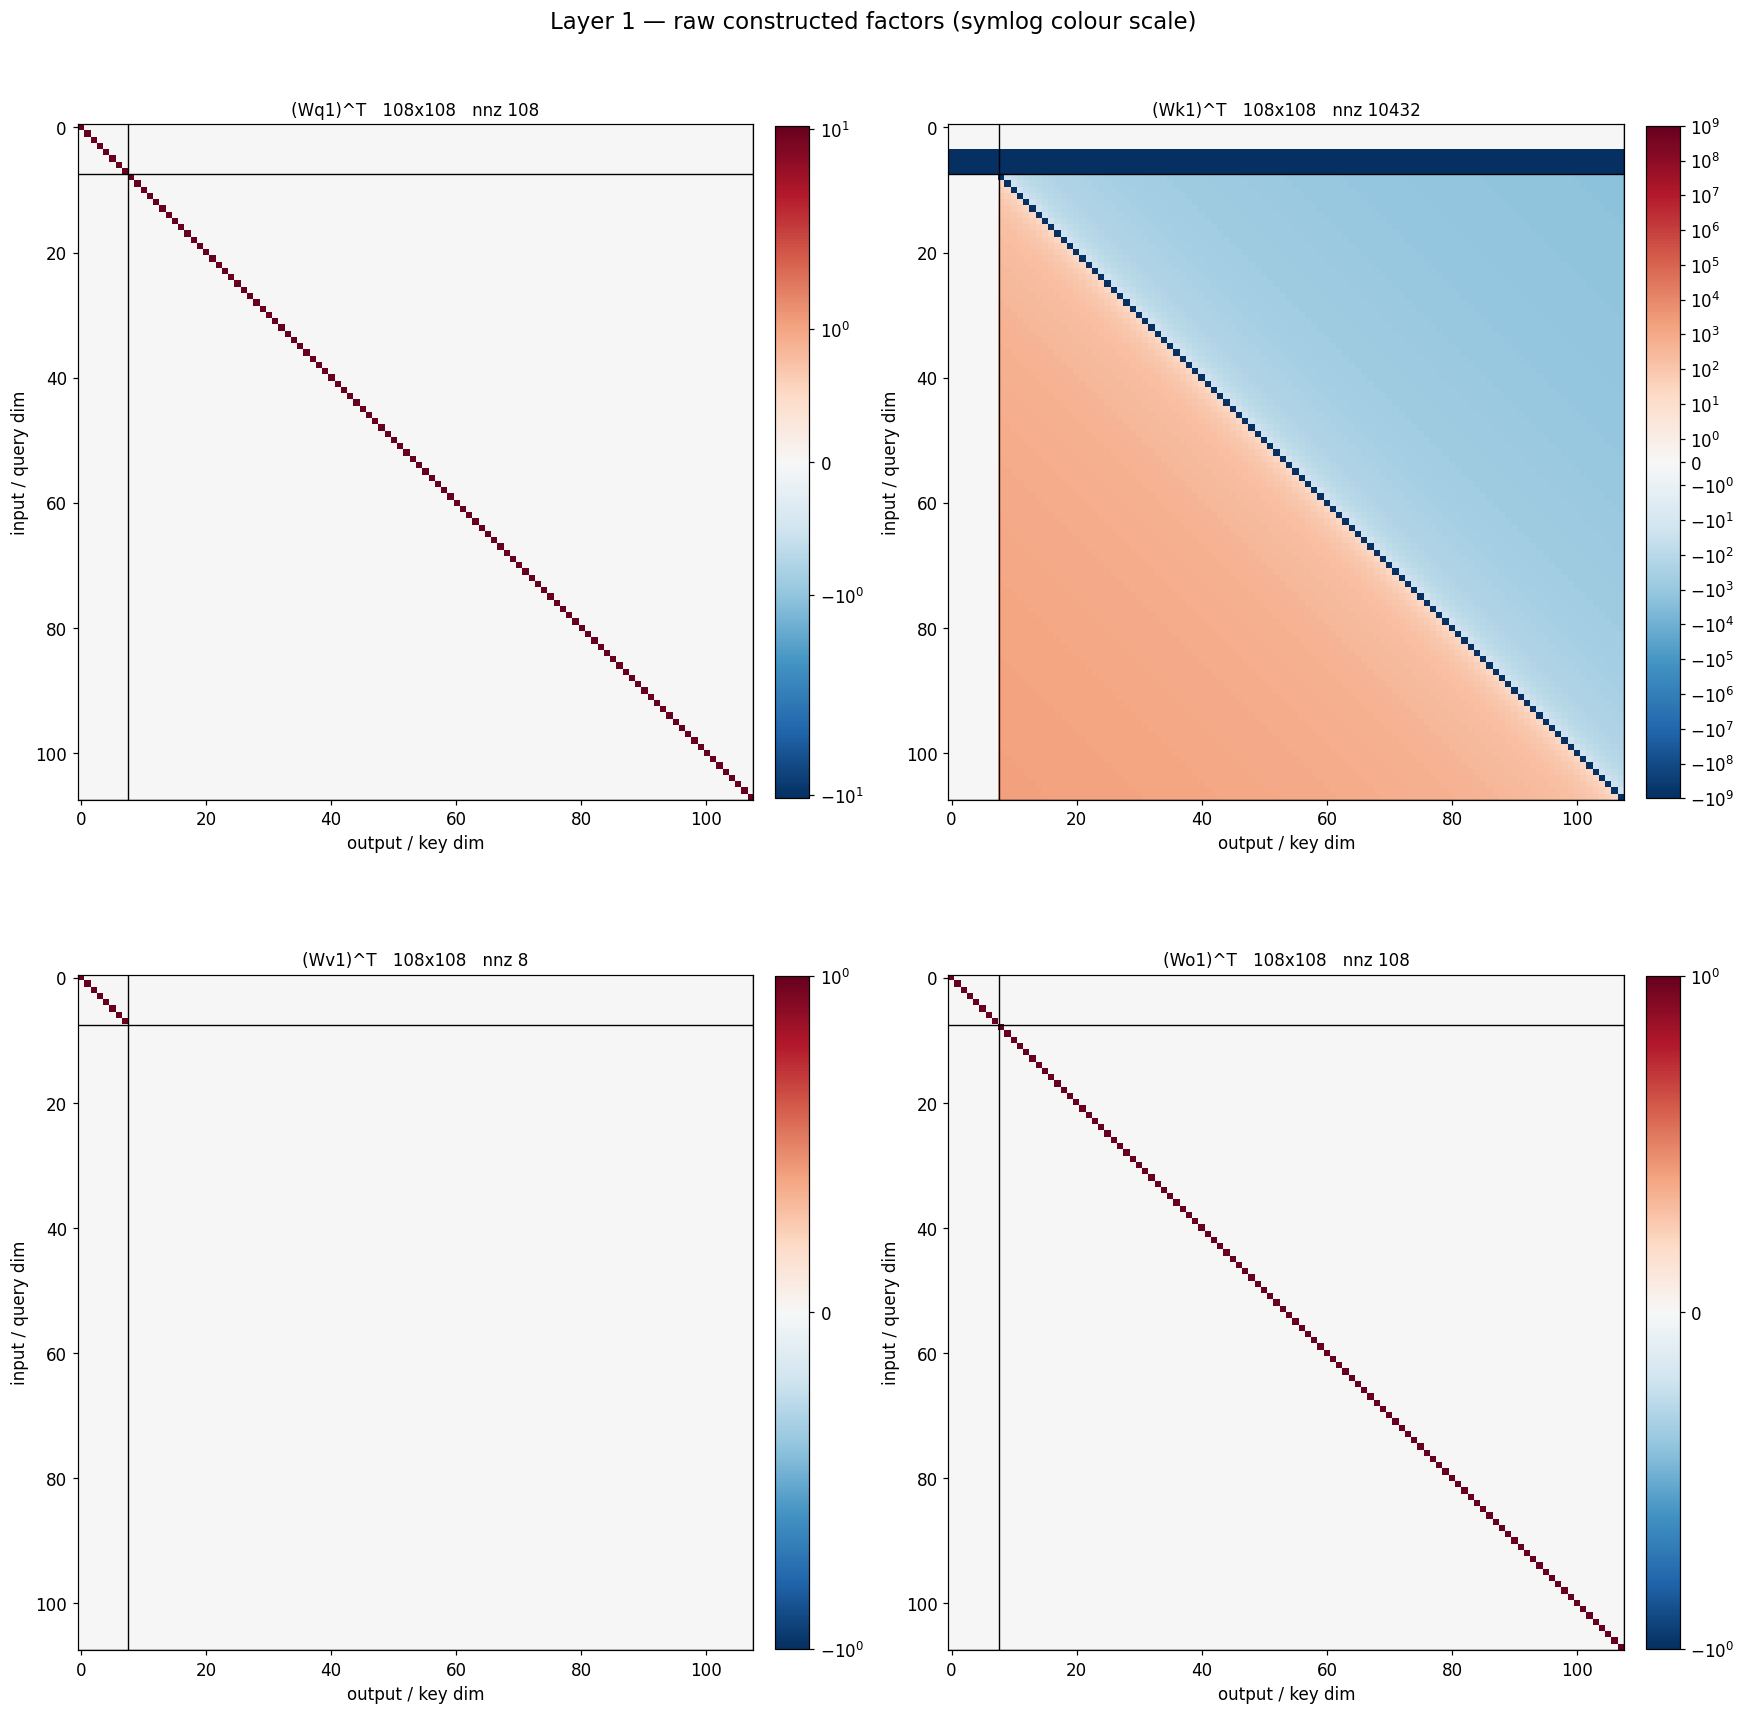

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, n in zip(axes.ravel(), ['(Wq1)^T', '(Wk1)^T', '(Wv1)^T', '(Wo1)^T']):
    im = show(ax, RAW[n], n)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle('Layer 1 — raw constructed factors (symlog colour scale)', fontsize=15, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'layer1_raw.png'), bbox_inches='tight')
plt.show()

## 2. Layer 2 — the four raw factors

$W_Q$ holds the two priorities: $1000\sqrt D$ on the own-token block (rows 0:4) and $50\sqrt D$ on
the layer-1 predecessor block (rows 108:112), plus the noise-trigger column. $W_K$ reads the
predecessor identity (rows 108:116) and applies the $-5\times10^4$ noise filter.

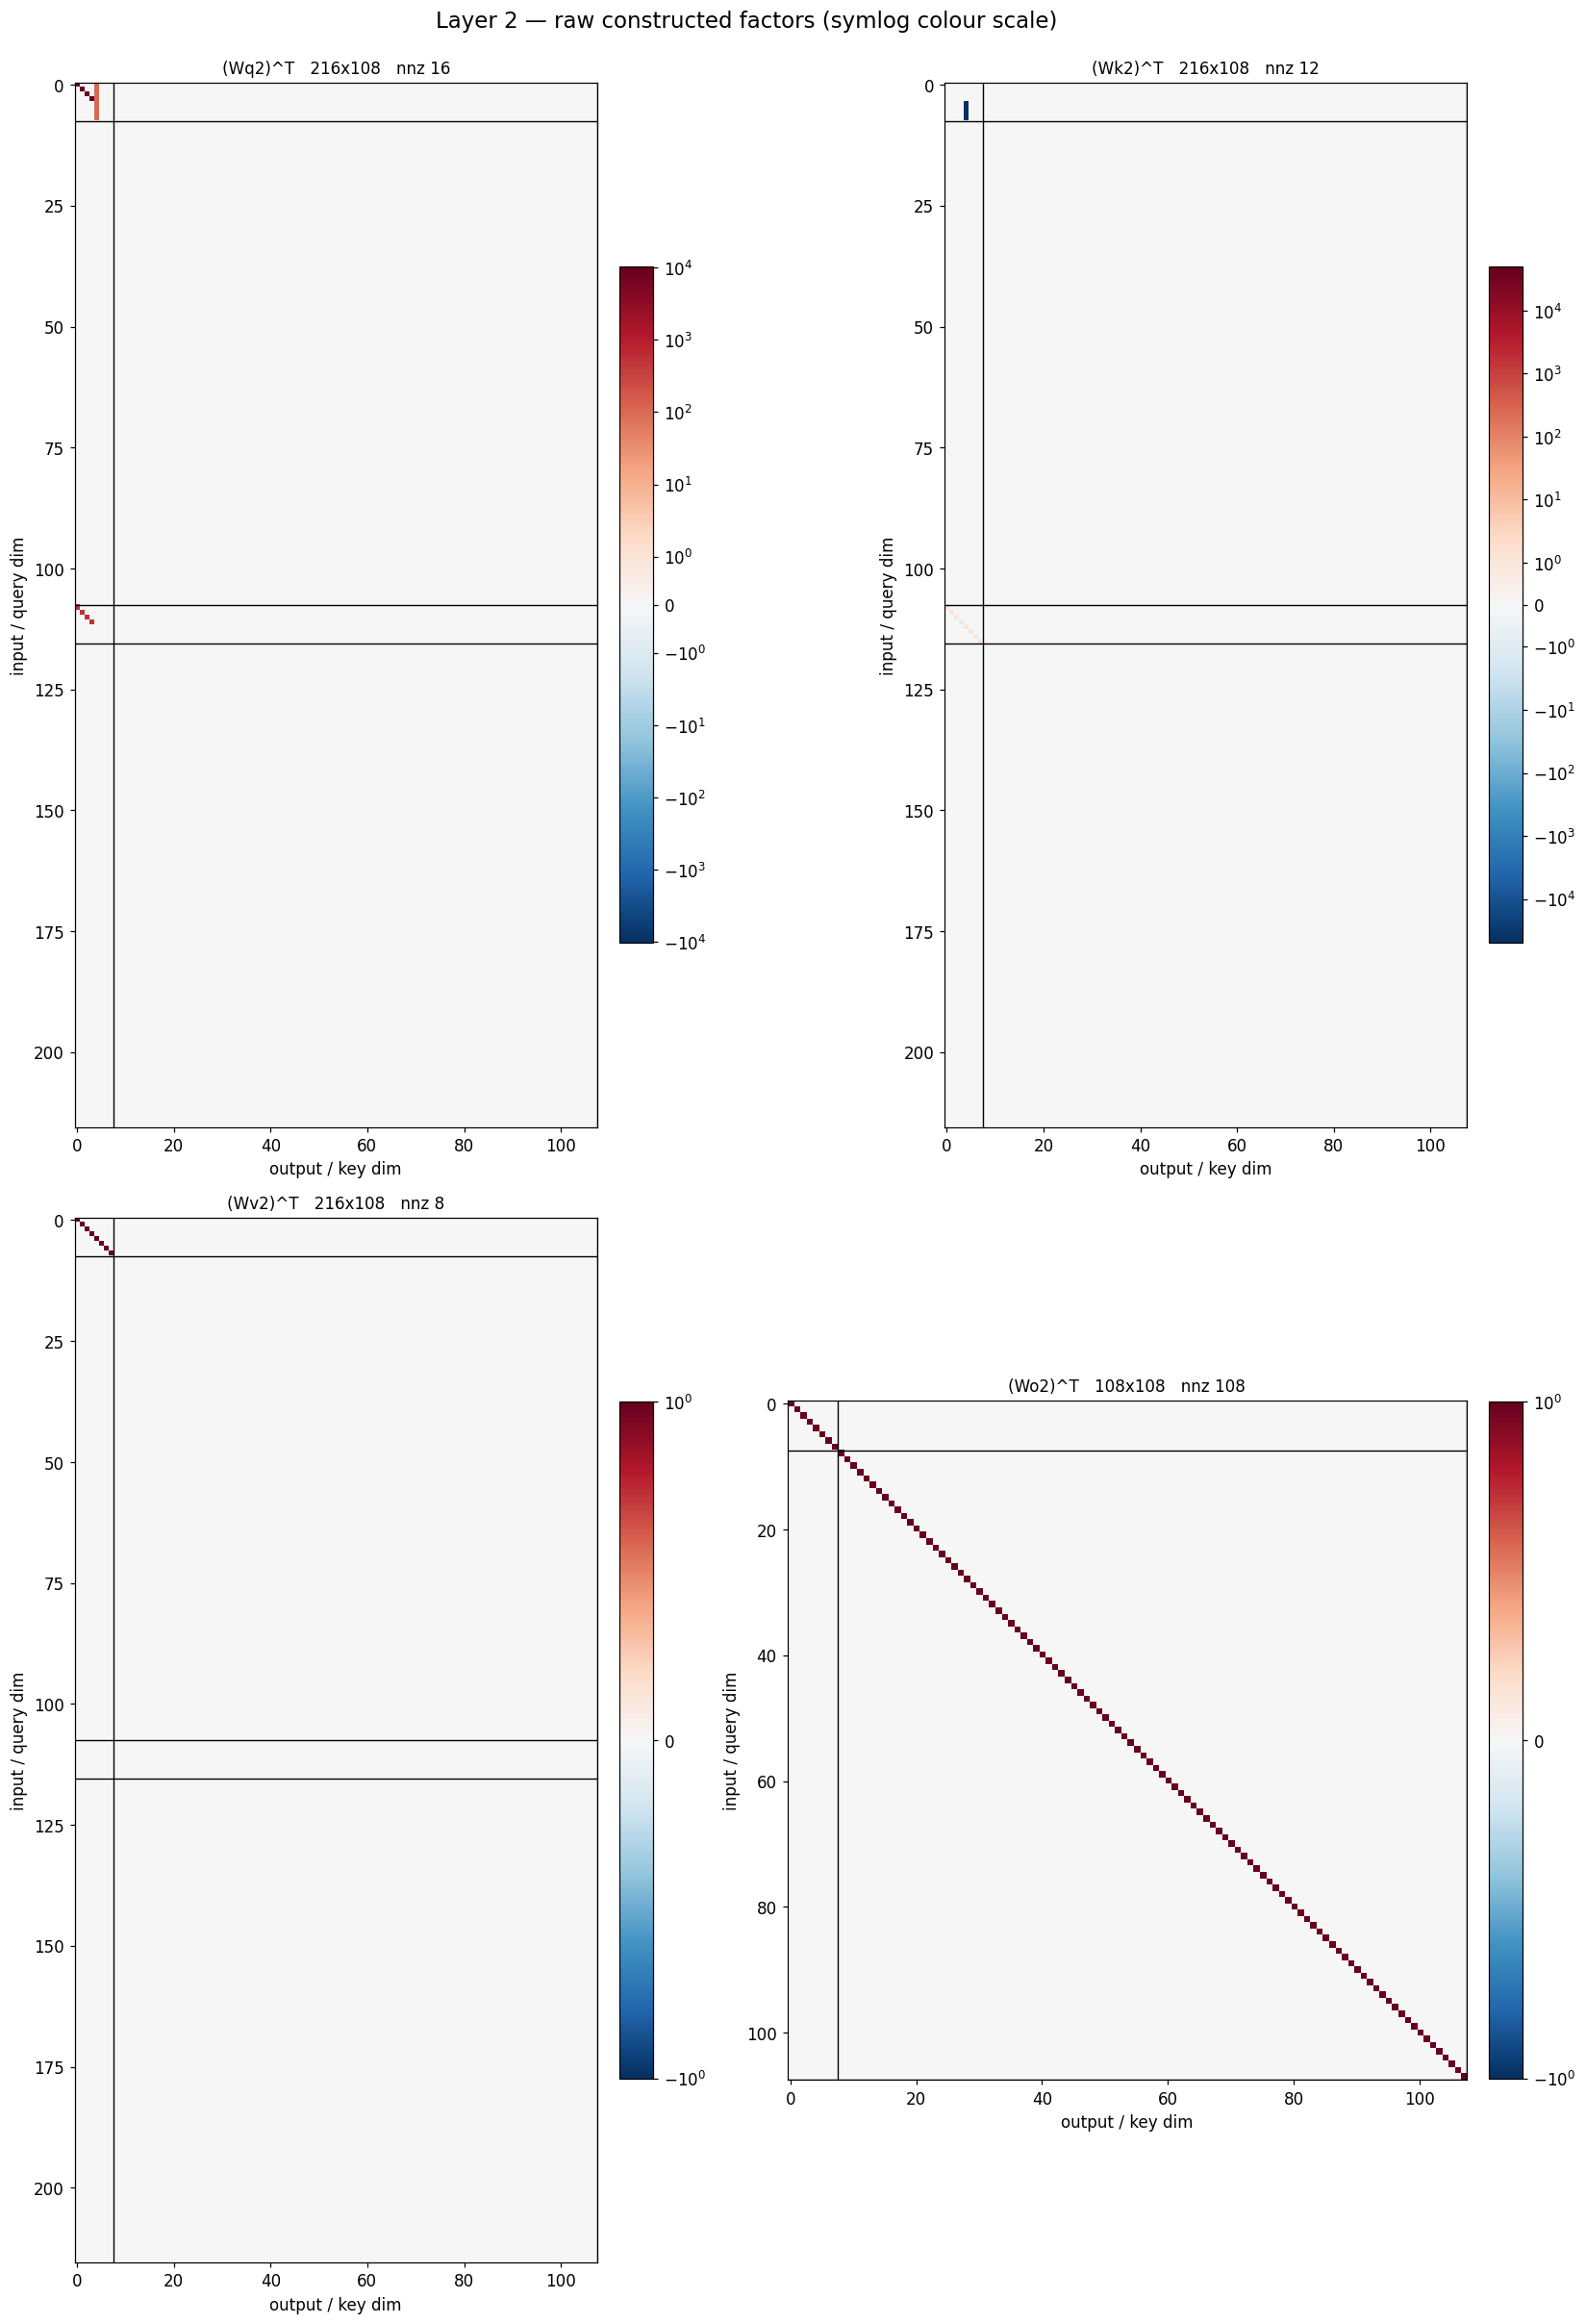

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 22))
for ax, n in zip(axes.ravel(), ['(Wq2)^T', '(Wk2)^T', '(Wv2)^T', '(Wo2)^T']):
    im = show(ax, RAW[n], n)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle('Layer 2 — raw constructed factors (symlog colour scale)', fontsize=15, y=0.997)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'layer2_raw.png'), bbox_inches='tight')
plt.show()

## 3. The products — what `combined` stores, and what GD must reach

$W_{qk}=W_Q^\top W_K$ and $W_{ov}=W_V^\top W_O^\top$. These four matrices **are** the target of
gradient descent in the combined parametrization.

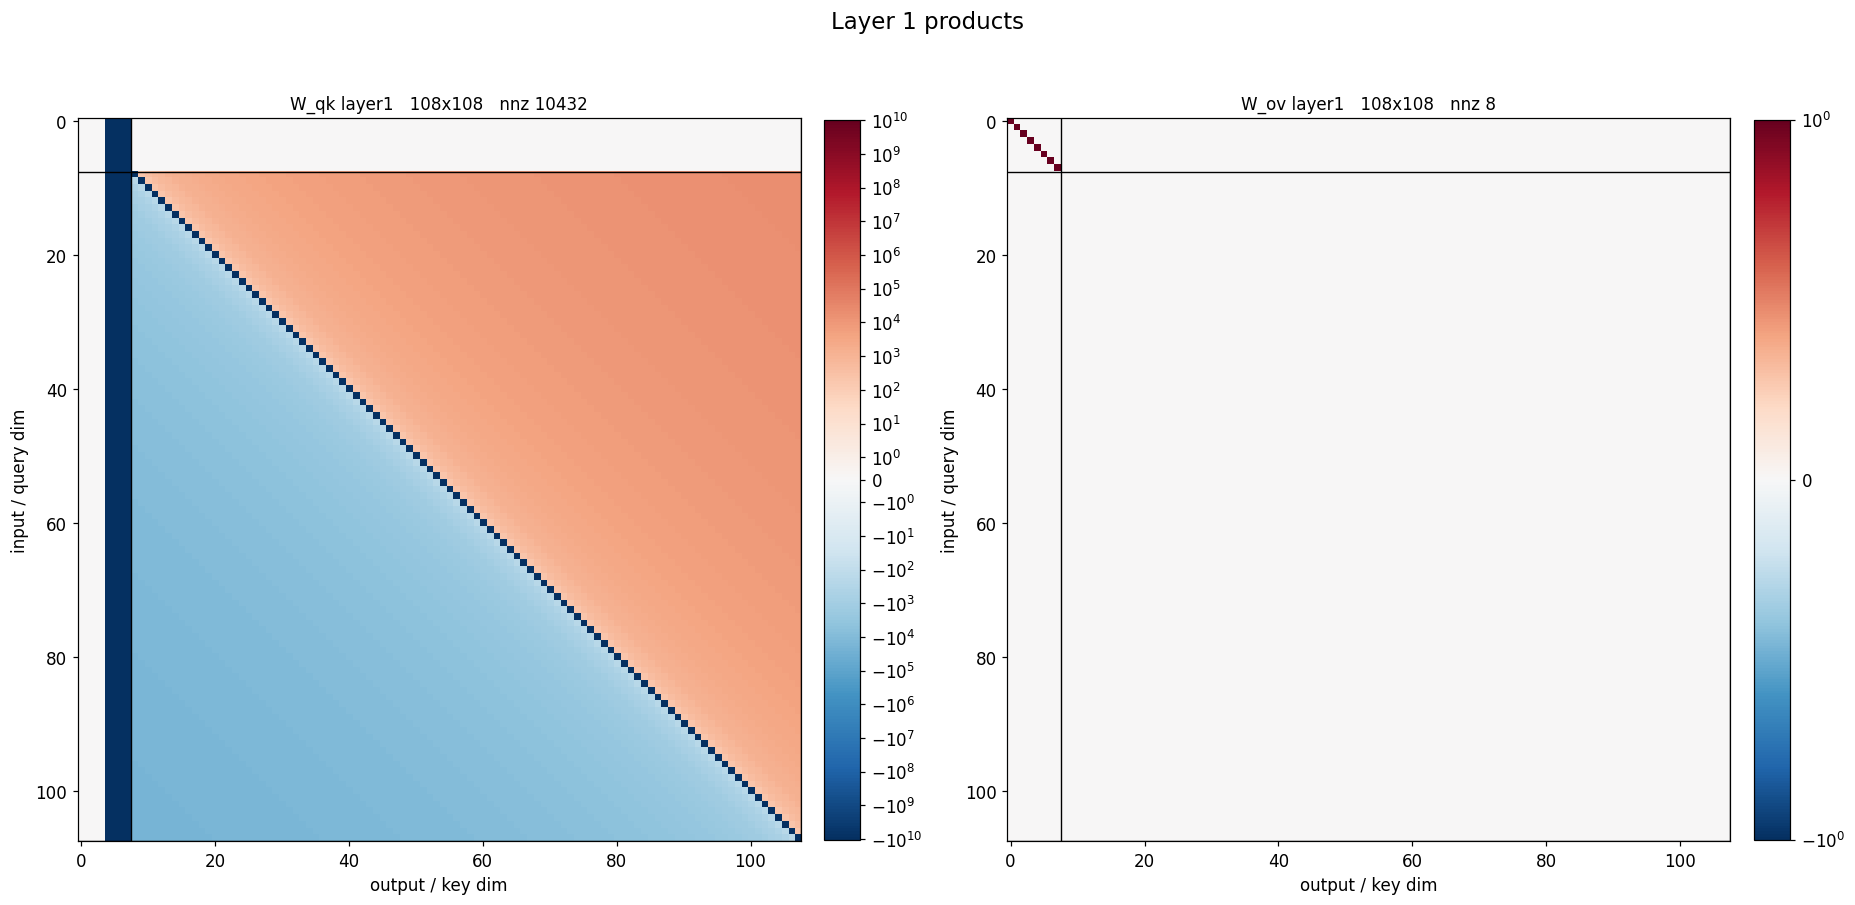

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))
for ax, n in zip(axes, ['W_qk layer1', 'W_ov layer1']):
    im = show(ax, PROD[n], n)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle('Layer 1 products', fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'layer1_products.png'), bbox_inches='tight')
plt.show()

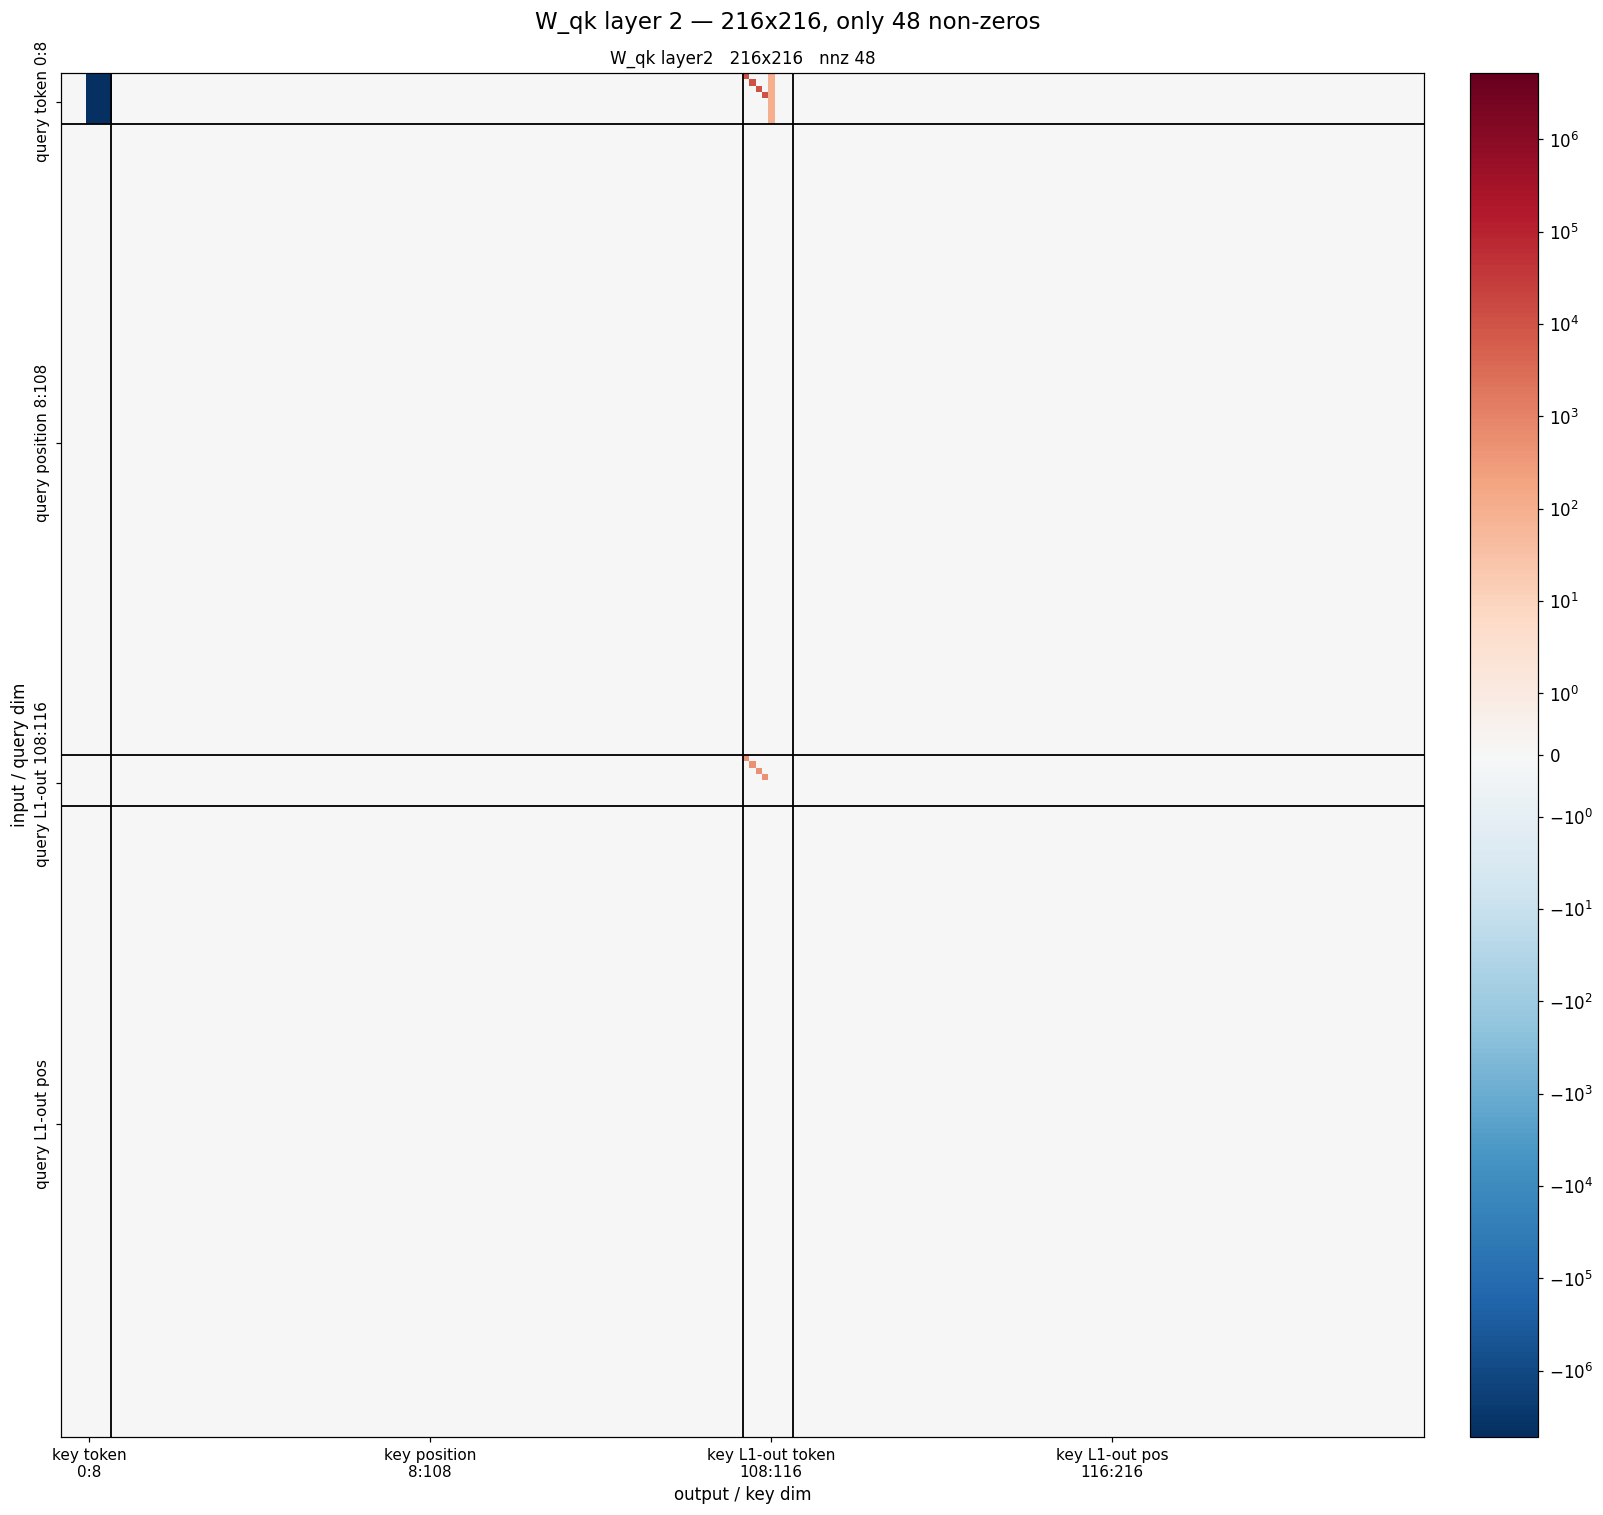

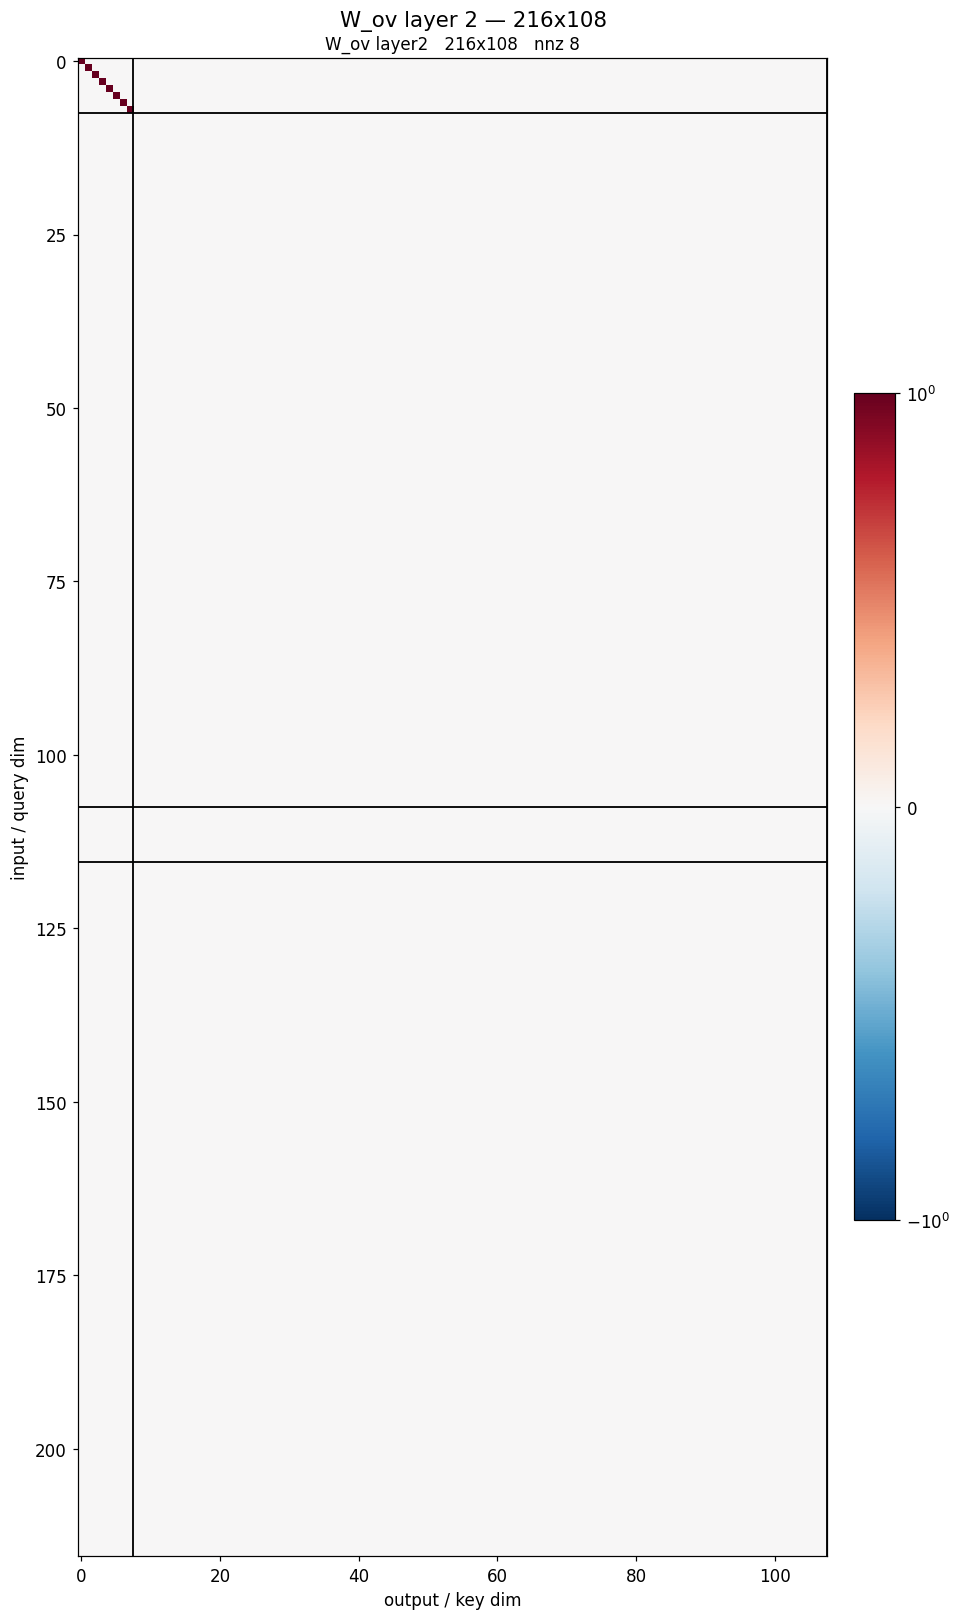

In [9]:
fig, ax = plt.subplots(figsize=(15, 14))
im = show(ax, PROD['W_qk layer2'], 'W_qk layer2', lw=1.2)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
ax.set_xticks([V // 2, V + T // 2, D + V // 2, D + V + (T // 2)])
ax.set_xticklabels(['key token\n0:8', 'key position\n8:108',
                    'key L1-out token\n108:116', 'key L1-out pos\n116:216'], fontsize=10)
ax.set_yticks([V // 2, V + T // 2, D + V // 2, D + V + (T // 2)])
ax.set_yticklabels(['query token 0:8', 'query position 8:108',
                    'query L1-out 108:116', 'query L1-out pos'], fontsize=10, rotation=90,
                   va='center')
fig.suptitle('W_qk layer 2 — 216x216, only 48 non-zeros', fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'layer2_wqk.png'), bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 15))
im = show(ax, PROD['W_ov layer2'], 'W_ov layer2', lw=1.2)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle('W_ov layer 2 — 216x108', fontsize=14)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'layer2_wov.png'), bbox_inches='tight')
plt.show()

## 4. Where every non-zero of the products lives

The full plots above are mostly empty by design — `W_qk` layer 2 has 48 non-zeros out of 46,656
cells. This lists them exhaustively.

In [10]:
for name in ['W_qk layer1', 'W_ov layer1', 'W_qk layer2', 'W_ov layer2']:
    M = PROD[name]
    nz = torch.nonzero(M)
    groups = {}
    for r, c in nz.tolist():
        groups.setdefault(round(float(M[r, c]), 3), []).append((r, c))
    print(f'{name}   shape {tuple(M.shape)}   nnz {len(nz)}')
    for val, cells_ in sorted(groups.items(), key=lambda kv: -abs(kv[0]))[:8]:
        rs = sorted({r for r, _ in cells_}); cs = sorted({c for _, c in cells_})
        rng = (f'rows {rs[0]}..{rs[-1]}' if len(rs) > 1 else f'row {rs[0]}')
        cng = (f'cols {cs[0]}..{cs[-1]}' if len(cs) > 1 else f'col {cs[0]}')
        print(f'   {val:>14,.3f}  x{len(cells_):<6d} {rng:22s} {cng}')
    if len(groups) > 8:
        print(f'   ... and {len(groups)-8} further distinct values '
              f'(the recency ramp: -207.846*(t_q - t_k))')
    print()

W_qk layer1   shape (108, 108)   nnz 10432
   -10,392,304,640.000  x532    rows 0..107            cols 4..107
       20,576.764  x1      row 8                  col 107
      -20,576.764  x1      row 107                col 8
       20,368.916  x2      rows 8..9              cols 106..107
      -20,368.916  x2      rows 106..107          cols 8..9
       20,161.070  x3      rows 8..10             cols 105..107
      -20,161.070  x3      rows 105..107          cols 8..10
       19,953.225  x4      rows 8..11             cols 104..107
   ... and 191 further distinct values (the recency ramp: -207.846*(t_q - t_k))

W_ov layer1   shape (108, 108)   nnz 8
            1.000  x8      rows 0..7              cols 0..7

W_qk layer2   shape (216, 216)   nnz 48
   -5,196,152.500  x32     rows 0..7              cols 4..7
       10,392.305  x4      rows 0..3              cols 108..111
          519.615  x4      rows 108..111          cols 108..111
          103.923  x8      rows 0..7              col 

## 5. Annotated close-ups

The full matrices show *where* the structure is; these show the actual numbers. Every cell value
is printed.

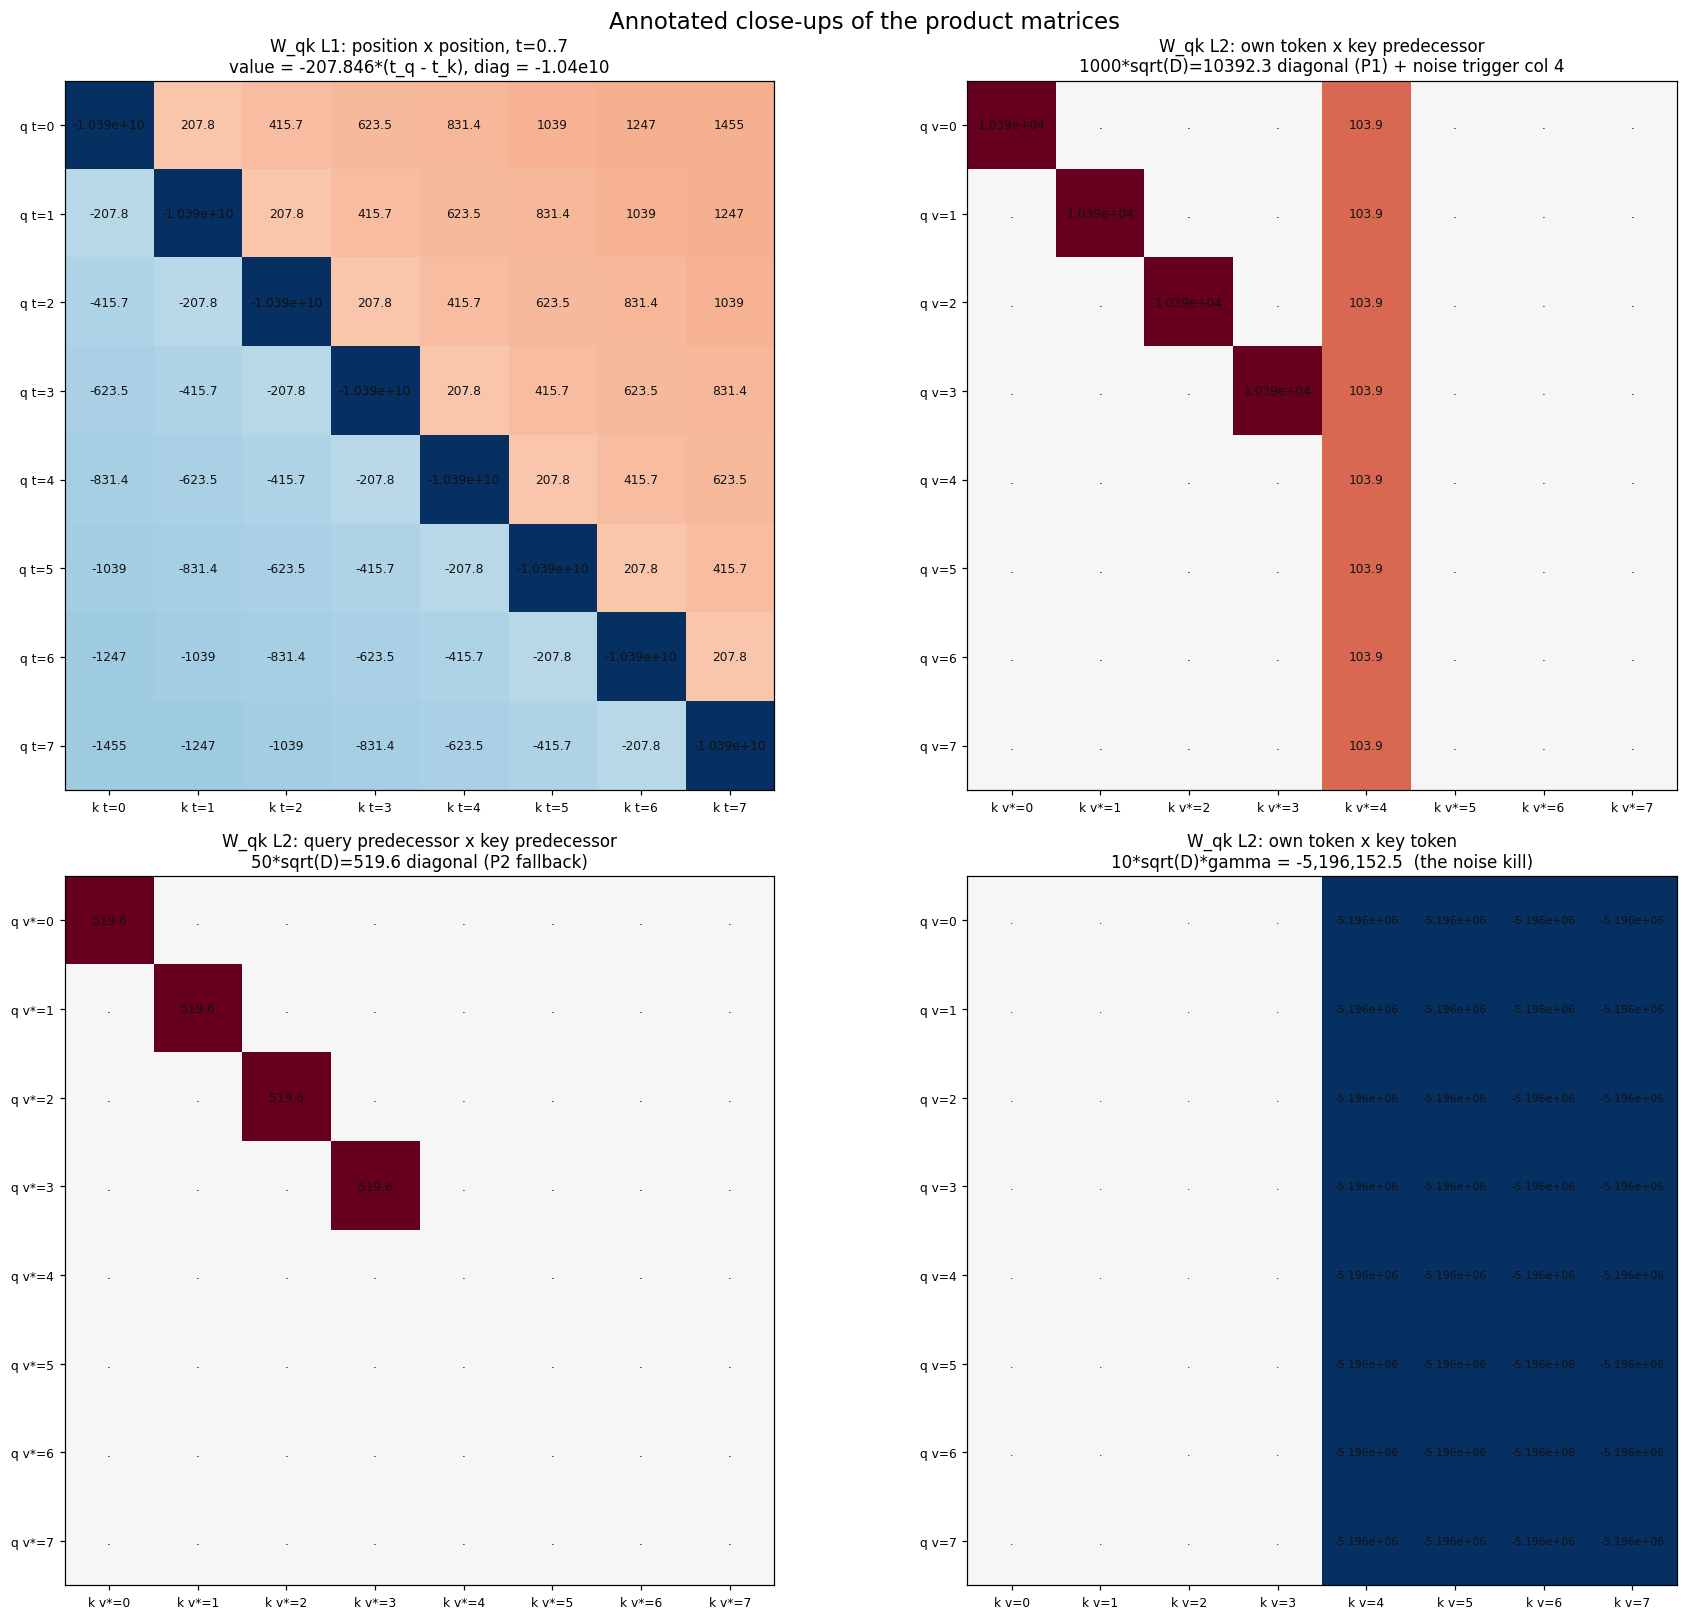

In [11]:
def annot(ax, M, r0, r1, c0, c1, title, rlab=None, clab=None, fmt='{:.4g}', fs=8):
    A = M[r0:r1, c0:c1].numpy()
    a = np.abs(A[A != 0]); vmax = float(a.max()) if a.size else 1.0
    ax.imshow(A, cmap='RdBu_r',
              norm=SymLogNorm(linthresh=1.0, linscale=0.6, vmin=-vmax, vmax=vmax, base=10),
              interpolation='nearest')
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            ax.text(j, i, fmt.format(A[i, j]) if A[i, j] != 0 else '.', ha='center',
                    va='center', fontsize=fs, color='#111111')
    ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
    ax.set_xticklabels(clab if clab else range(c0, c1), fontsize=8)
    ax.set_yticklabels(rlab if rlab else range(r0, r1), fontsize=8)
    ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(2, 2, figsize=(17, 15))
annot(axes[0][0], PROD['W_qk layer1'], V, V + 8, V, V + 8,
      'W_qk L1: position x position, t=0..7\nvalue = -207.846*(t_q - t_k), diag = -1.04e10',
      rlab=[f'q t={i}' for i in range(8)], clab=[f'k t={i}' for i in range(8)])
annot(axes[0][1], PROD['W_qk layer2'], 0, V, D, D + V,
      'W_qk L2: own token x key predecessor\n1000*sqrt(D)=10392.3 diagonal (P1) + noise trigger col 4',
      rlab=[f'q v={i}' for i in range(V)], clab=[f'k v*={i}' for i in range(V)])
annot(axes[1][0], PROD['W_qk layer2'], D, D + V, D, D + V,
      'W_qk L2: query predecessor x key predecessor\n50*sqrt(D)=519.6 diagonal (P2 fallback)',
      rlab=[f'q v*={i}' for i in range(V)], clab=[f'k v*={i}' for i in range(V)])
annot(axes[1][1], PROD['W_qk layer2'], 0, V, 0, V,
      'W_qk L2: own token x key token\n10*sqrt(D)*gamma = -5,196,152.5  (the noise kill)',
      rlab=[f'q v={i}' for i in range(V)], clab=[f'k v={i}' for i in range(V)], fs=7)
fig.suptitle('Annotated close-ups of the product matrices', fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'closeups.png'), bbox_inches='tight')
plt.show()

## 6. Summary — the target pattern

| matrix | shape | nnz | the pattern GD has to reach |
|---|---|---|---|
| $W_{qk}$ L1 | 108×108 | 10432 | position×position ramp $-207.85\,(t_q-t_k)$, diagonal $-1.04{\times}10^{10}$, noise-token rows $-1.04{\times}10^{10}$ |
| $W_{ov}$ L1 | 108×108 | 8 | $I_8$ at [0:8, 0:8] — keep the token one-hot, drop position |
| $W_{qk}$ L2 | 216×216 | 48 | $10392.3\,I_4$ at (own token)×(key predecessor); $519.6\,I_4$ at (predecessor)×(predecessor); $103.9$ noise trigger; $-5.2{\times}10^6$ noise kill |
| $W_{ov}$ L2 | 216×108 | 8 | $I_8$ at [0:8, 0:8] — copy the attended position's own token |

Two things stand out as targets:

1. **Extreme sparsity.** Layer 2's QK circuit needs 48 non-zeros out of 46,656 — 0.10% of cells.
   Everything else must be exactly zero.
2. **Extreme dynamic range.** Within one matrix the meaningful values span
   $10^2$ to $10^{10}$, and the sign structure matters: the large negatives are hard
   suppressions ("never attend here"), the moderate positives are the matches.

Gradient descent starting from $\mathcal N(0, 1/\sqrt{\text{fan-in}})$ — entries of order
$0.1$ — has to travel eight orders of magnitude to reach the suppression terms. It never does;
what it finds instead is a low-amplitude pattern with the same *ordering*, which is enough because
only the softmax's argmax matters. That comparison is in `analyse_qk_train.ipynb`.

---

# 7. What gradient descent actually learned

Same matrices, same plotting format, from the latest run:
`qkonly_opt-adam_lr-0.005_b-256_init-normal_ep-1000` — 7 thresholds x 2 architectures, 1000
epochs, trained by `train_qk_only.py`.

In that run **only the QK circuit is free**. $W_{ov}$, the unembedding and the pre-log bias are
pinned to the construction, so:

* `separate` learns $W_Q, W_K$ for both layers -> effective $W_{qk}=W_Q^\top W_K$
* `combined` learns $W_{qk}$ directly
* $W_{ov}$ is frozen in both and is shown only as a check

Set `THR` below to look at a different threshold.

In [18]:
import glob
CELL = 'qkonly_opt-adam_lr-0.005_b-256_init-normal_ep-1000'
CDIR = os.path.join('runs', CELL)
THR  = 0.5
ARCHS = ['separate', 'combined']

import importlib.util
_s = importlib.util.spec_from_file_location('qk', 'train_qk_only.py')
QK = importlib.util.module_from_spec(_s); _s.loader.exec_module(QK)

def load(arch, thr):
    m = QK.QKOnlyTransformer(V, T, D, VS, thr, arch)
    m.load_state_dict(torch.load(os.path.join(CDIR, f'model_{arch}_seed0_x_{thr}.pth'),
                                 map_location='cpu', weights_only=True))
    return m.eval()

def eff(model):
    qk, ov, raw = [], [], {}
    for i, layer in enumerate((model.layer1, model.layer2), 1):
        if hasattr(layer, 'W_qk'):
            qk.append(layer.W_qk.detach()); ov.append(layer.W_ov.detach())
        else:
            qk.append(layer.W_q.weight.detach().t() @ layer.W_k.weight.detach())
            ov.append(layer.W_v.weight.detach().t() @ layer.W_o.weight.detach().t())
            raw[f'(Wq{i})^T learned'] = layer.W_q.weight.detach().t()
            raw[f'(Wk{i})^T learned'] = layer.W_k.weight.detach().t()
    return qk, ov, raw

MODELS = {a: load(a, THR) for a in ARCHS}
QKL = {a: eff(MODELS[a])[0] for a in ARCHS}
OVL = {a: eff(MODELS[a])[1] for a in ARCHS}
RAWL = eff(MODELS['separate'])[2]

print(f'cell {CELL}   alpha = {THR}\n')
print(f'{"matrix":22s} {"shape":>12s} {"nnz":>7s} {"min":>13s} {"max":>13s} {"||.||_F":>12s} '
      f'{"vs constr":>11s}')
for i, key in ((0, 'W_qk layer1'), (1, 'W_qk layer2')):
    c = PROD[key]
    print(f'{"construction " + key:22s} {str(tuple(c.shape)):>12s} {int((c!=0).sum()):7d} '
          f'{float(c.min()):13.4g} {float(c.max()):13.4g} {float(c.norm()):12.4g} {1.0:11.3g}')
    for a in ARCHS:
        M = QKL[a][i]
        print(f'{a + " " + key:22s} {str(tuple(M.shape)):>12s} {int((M!=0).sum()):7d} '
              f'{float(M.min()):13.4g} {float(M.max()):13.4g} {float(M.norm()):12.4g} '
              f'{float(M.norm()/c.norm()):11.3g}')
    print()
for i, key in ((0, 'W_ov layer1'), (1, 'W_ov layer2')):
    ok = all(torch.equal(OVL[a][i], PROD[key]) for a in ARCHS)
    print(f'{key}: identical to the construction in both archs -> {ok}')

cell qkonly_opt-adam_lr-0.005_b-256_init-normal_ep-1000   alpha = 0.5

matrix                        shape     nnz           min           max      ||.||_F   vs constr
construction W_qk layer1   (108, 108)   10432    -1.039e+10     2.058e+04    2.397e+11           1
separate W_qk layer1     (108, 108)   11664        -687.7          1139    1.701e+04     7.1e-08
combined W_qk layer1     (108, 108)   11664        -155.1         103.7         5283     2.2e-08

construction W_qk layer2   (216, 216)      48    -5.196e+06     1.039e+04    2.939e+07           1
separate W_qk layer2     (216, 216)   46656        -340.3           215         1664    5.66e-05
combined W_qk layer2     (216, 216)   46656        -97.12         69.12        976.4    3.32e-05

W_ov layer1: identical to the construction in both archs -> True
W_ov layer2: identical to the construction in both archs -> True


## 7.1 The learned raw factors ($W_Q, W_K$) — `separate` only

`combined` has no $W_Q$ / $W_K$ to show; it stores the product directly. These four are what GD
actually moves in the separate parametrization, and they are **not** individually meaningful —
only their product is (the $(M^{-\top}W_Q,\,MW_K)$ gauge). Shown for completeness.

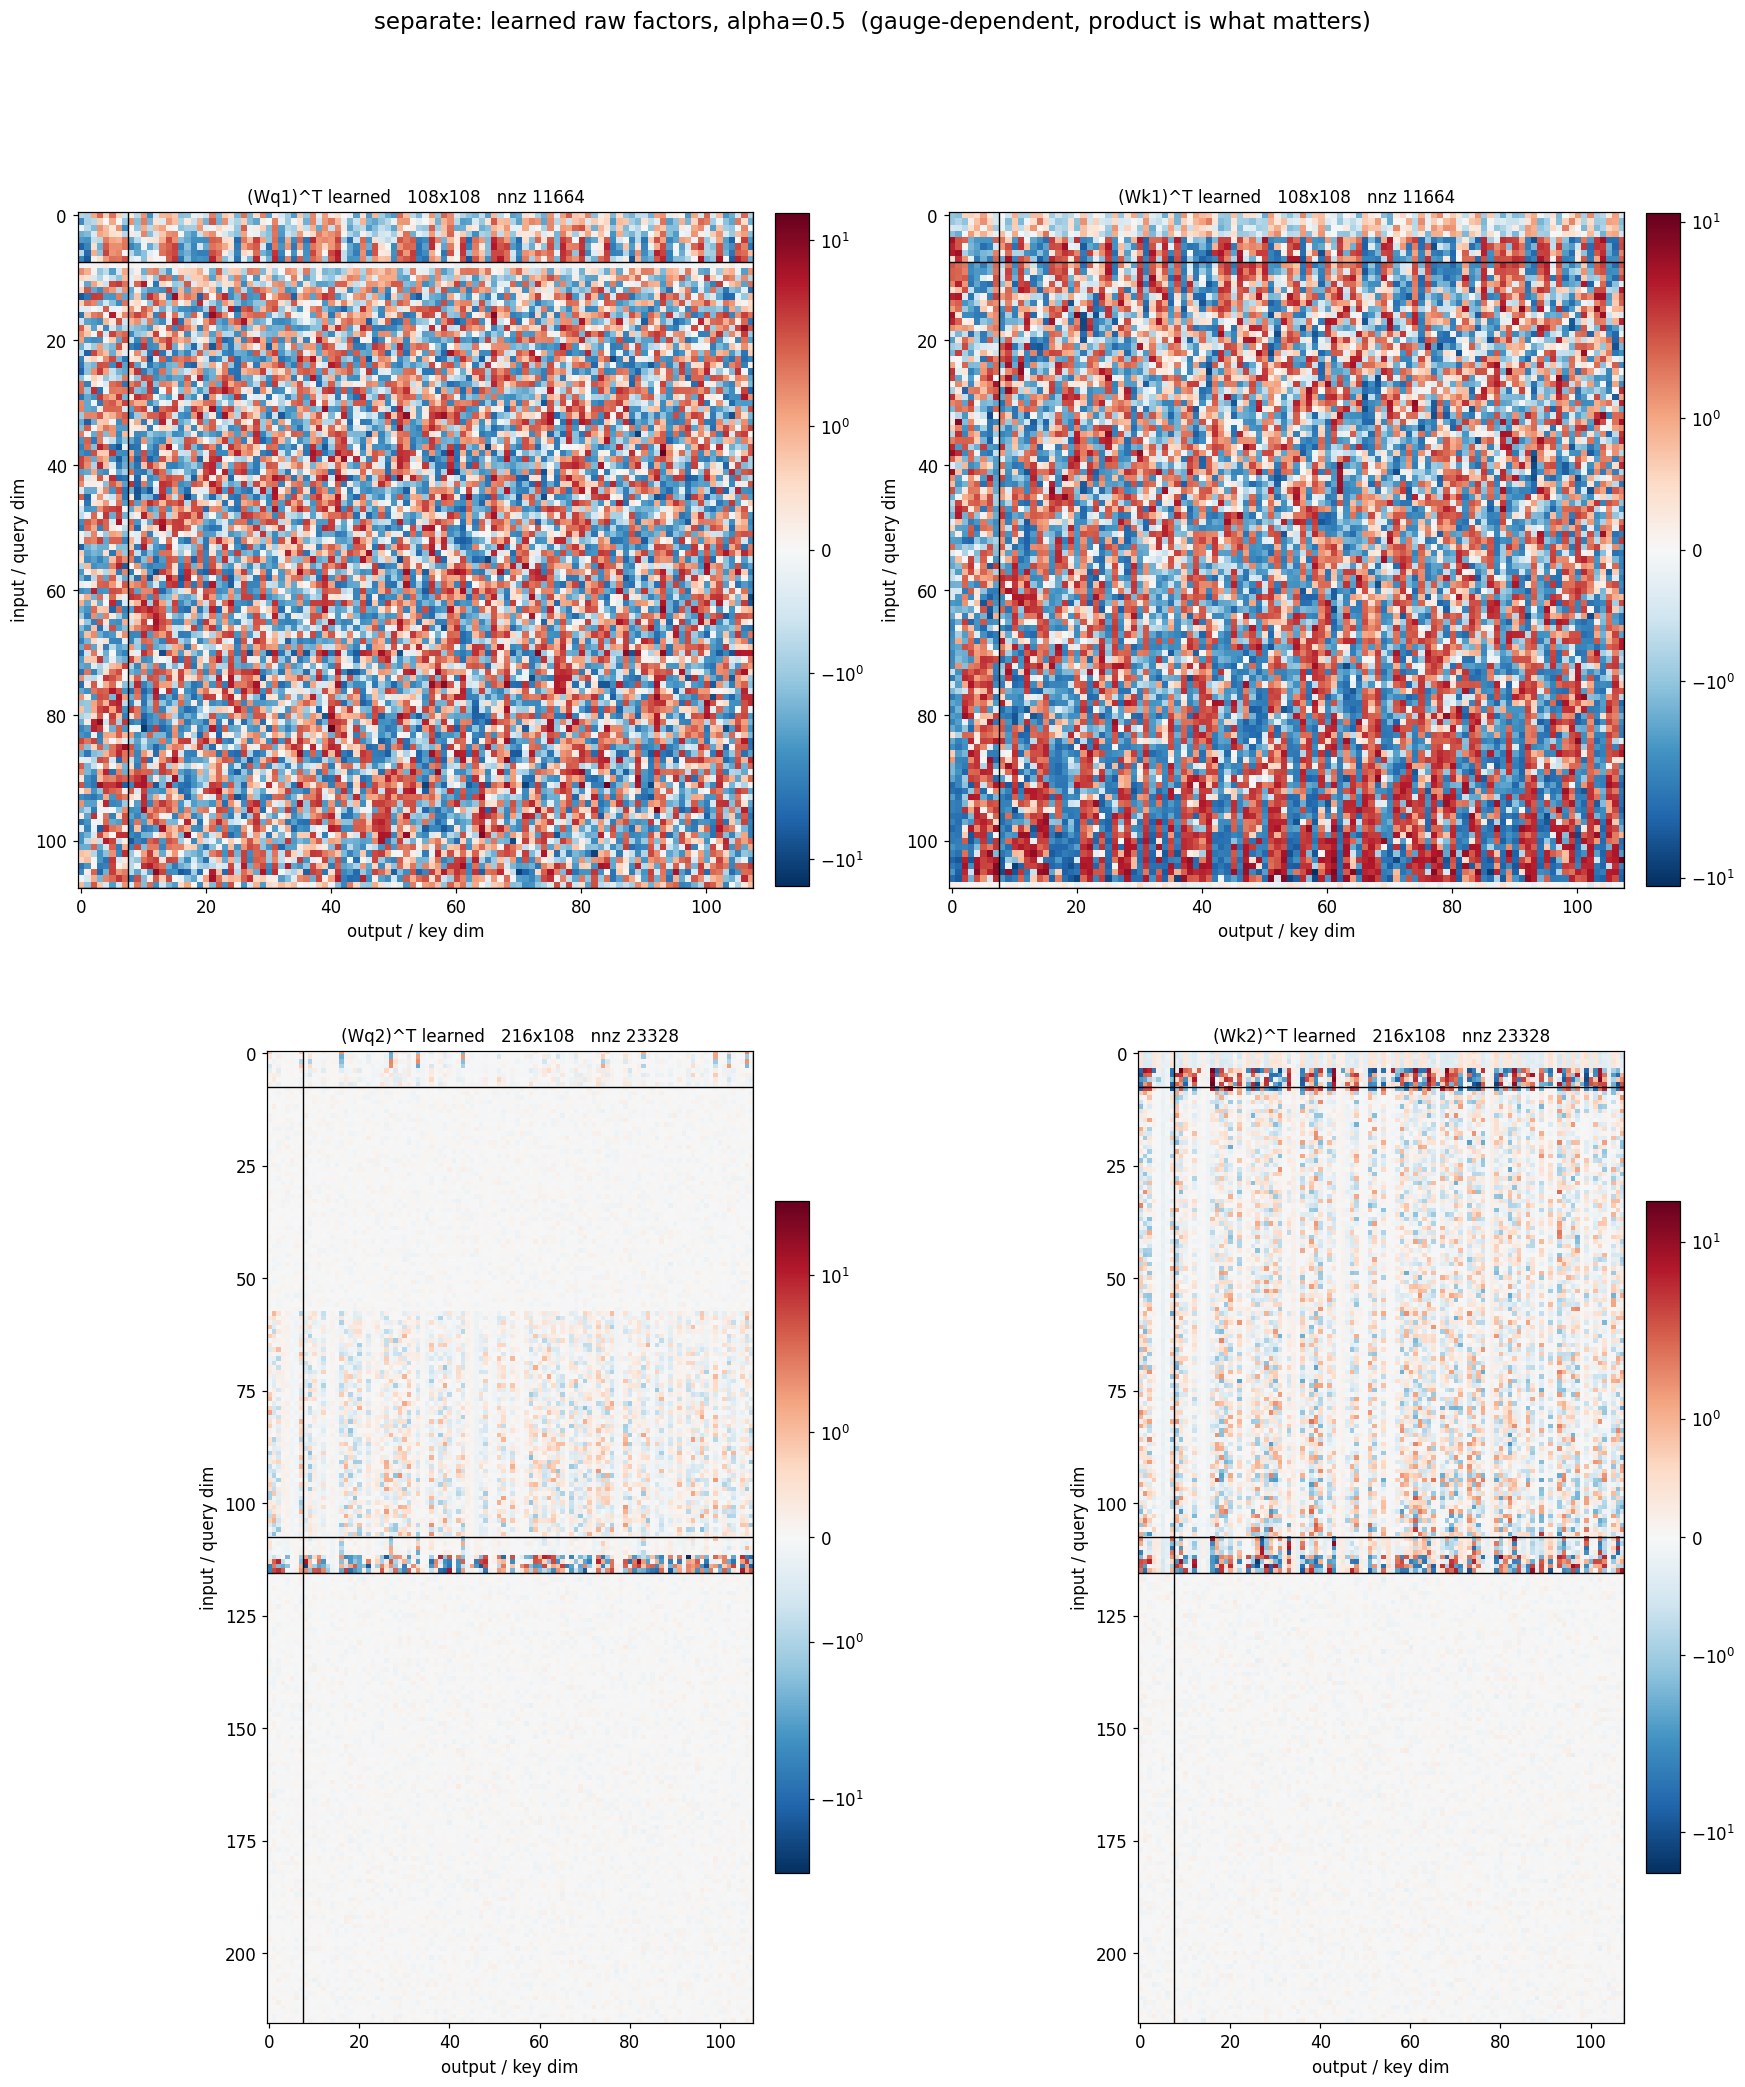

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 19))
for ax, n in zip(axes.ravel(), ['(Wq1)^T learned', '(Wk1)^T learned',
                                '(Wq2)^T learned', '(Wk2)^T learned']):
    im = show(ax, RAWL[n], n)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'separate: learned raw factors, alpha={THR}  (gauge-dependent, product is what matters)',
             fontsize=15, y=0.997)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'learned_raw_separate_a{THR}.png'), bbox_inches='tight')
plt.show()

## 7.2 $W_{qk}$ layer 1 — construction vs learned

Same colour treatment as section 3, but note each panel carries **its own scale**: the learned
matrices are eight orders of magnitude smaller than the construction, so a shared scale would
render them blank.

What to look for: the construction has a dark stripe at **columns 4:8** (never attend to a noise
key), a dark diagonal (never attend to yourself), and a smooth antisymmetric ramp whose
lower triangle is least-negative next to the diagonal.

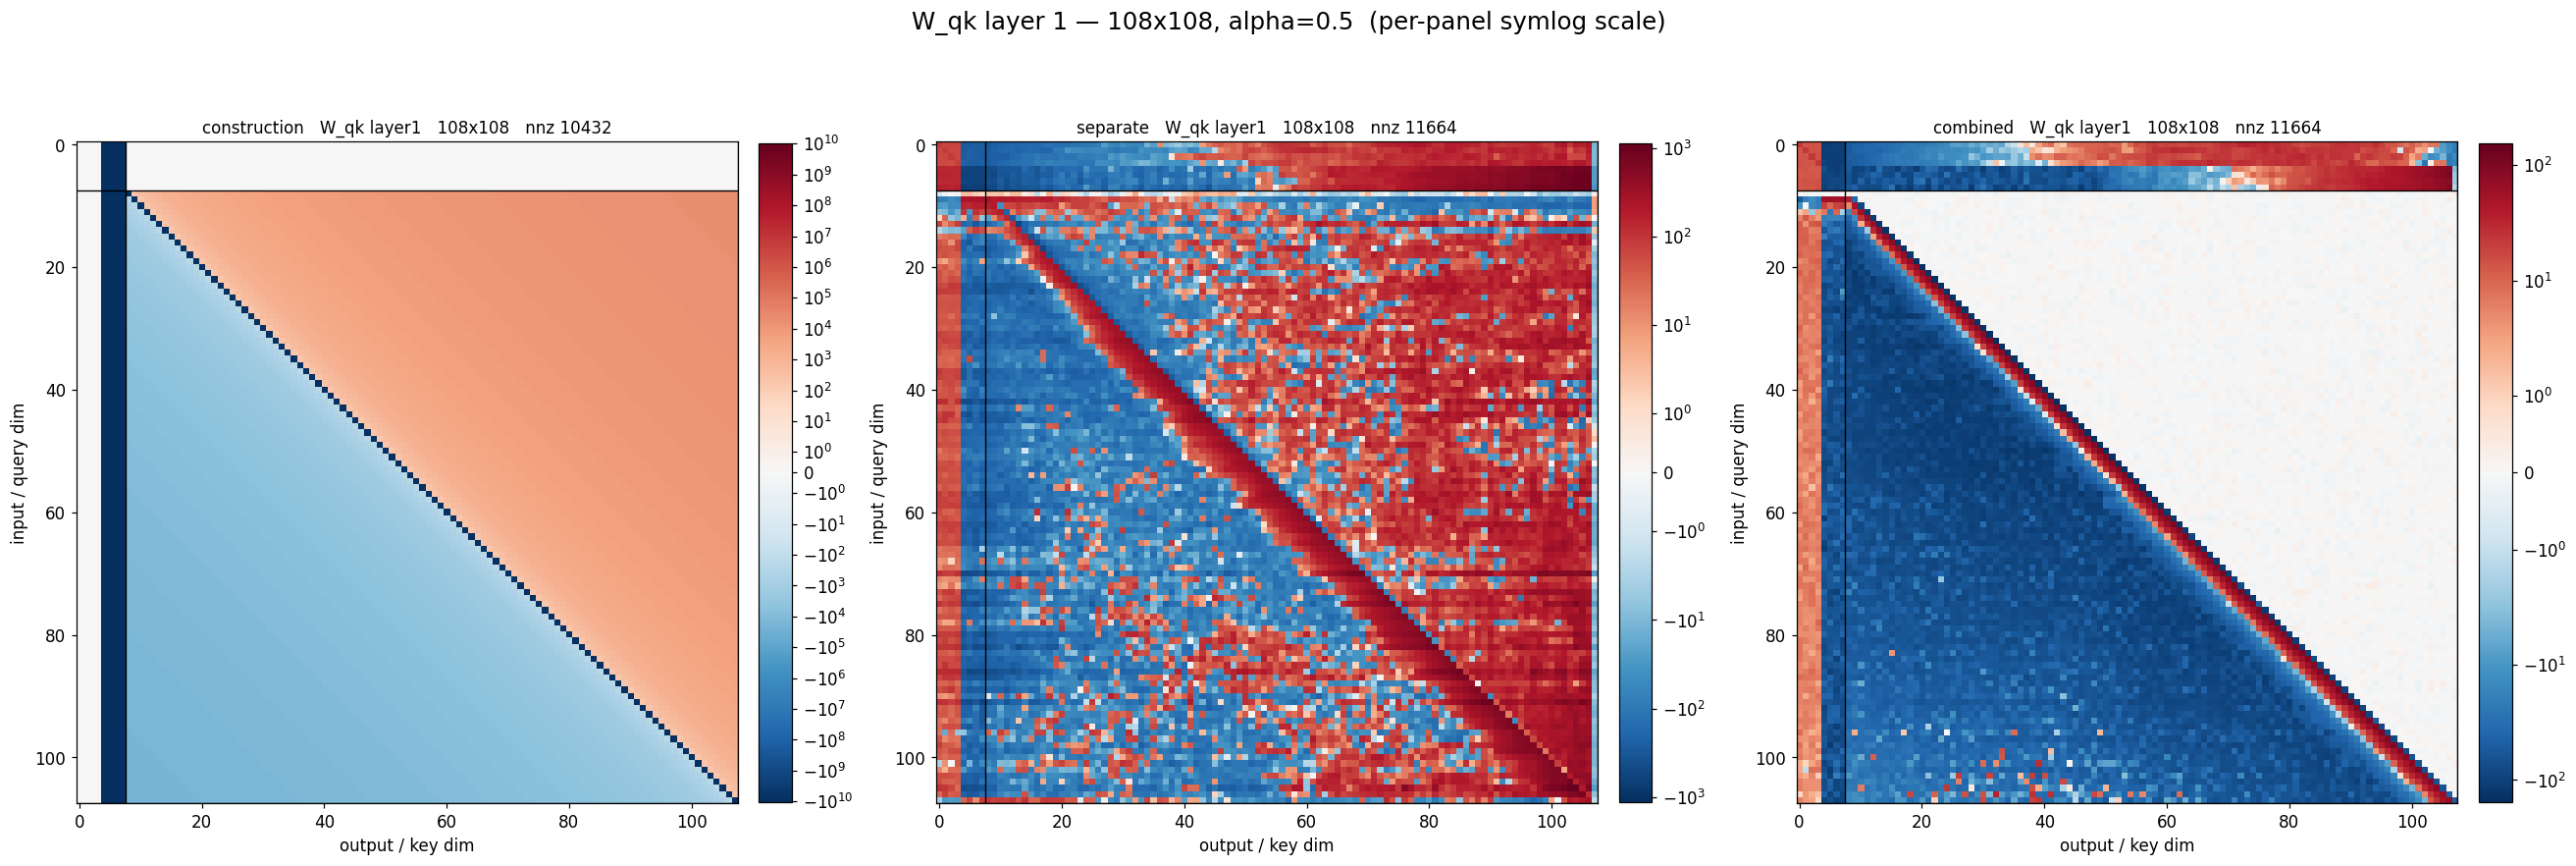

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8.5))
for ax, (nm, M) in zip(axes, [('construction', PROD['W_qk layer1'])] +
                             [(a, QKL[a][0]) for a in ARCHS]):
    im = show(ax, M, f'{nm}   W_qk layer1')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'W_qk layer 1 — 108x108, alpha={THR}  (per-panel symlog scale)', fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'learned_wqk1_a{THR}.png'), bbox_inches='tight')
plt.show()

## 7.3 $W_{qk}$ layer 2 — construction vs learned

The construction is 48 non-zeros in 46,656 cells. The learned matrices are fully dense.

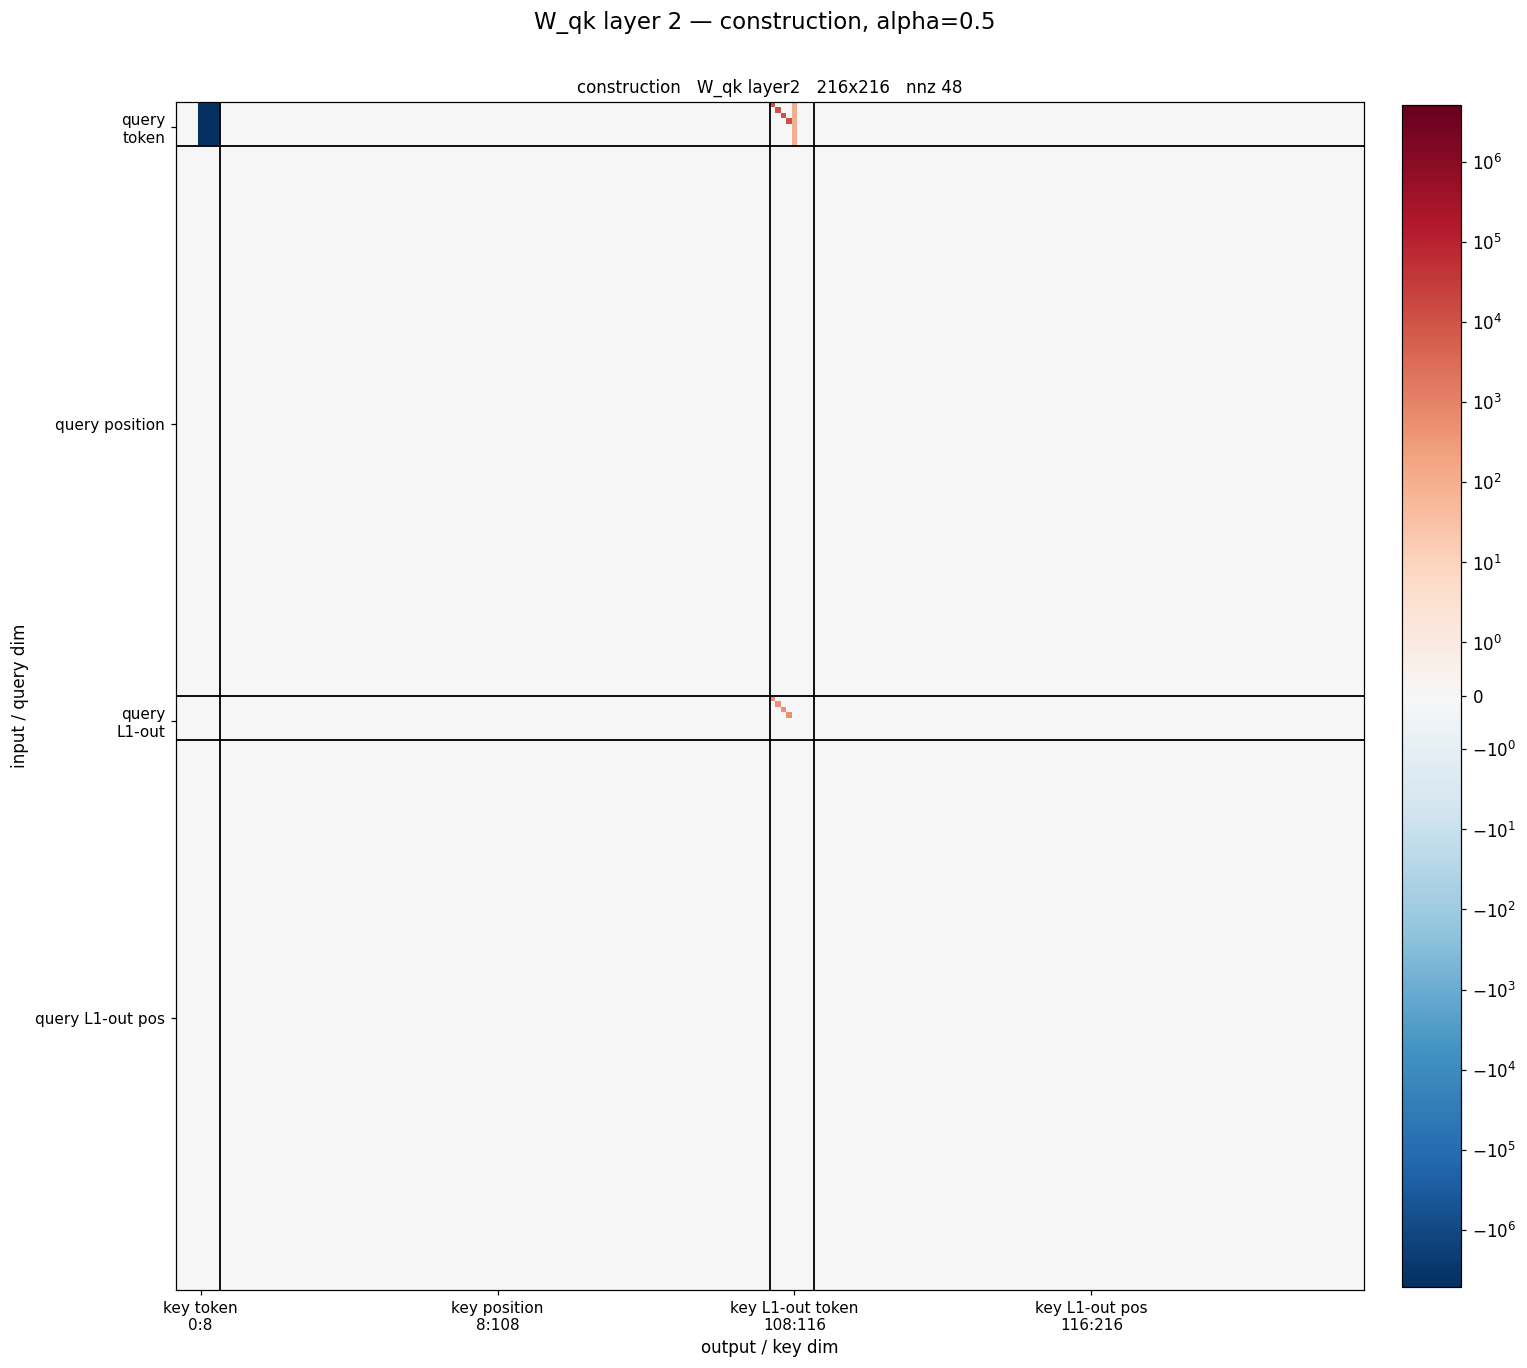

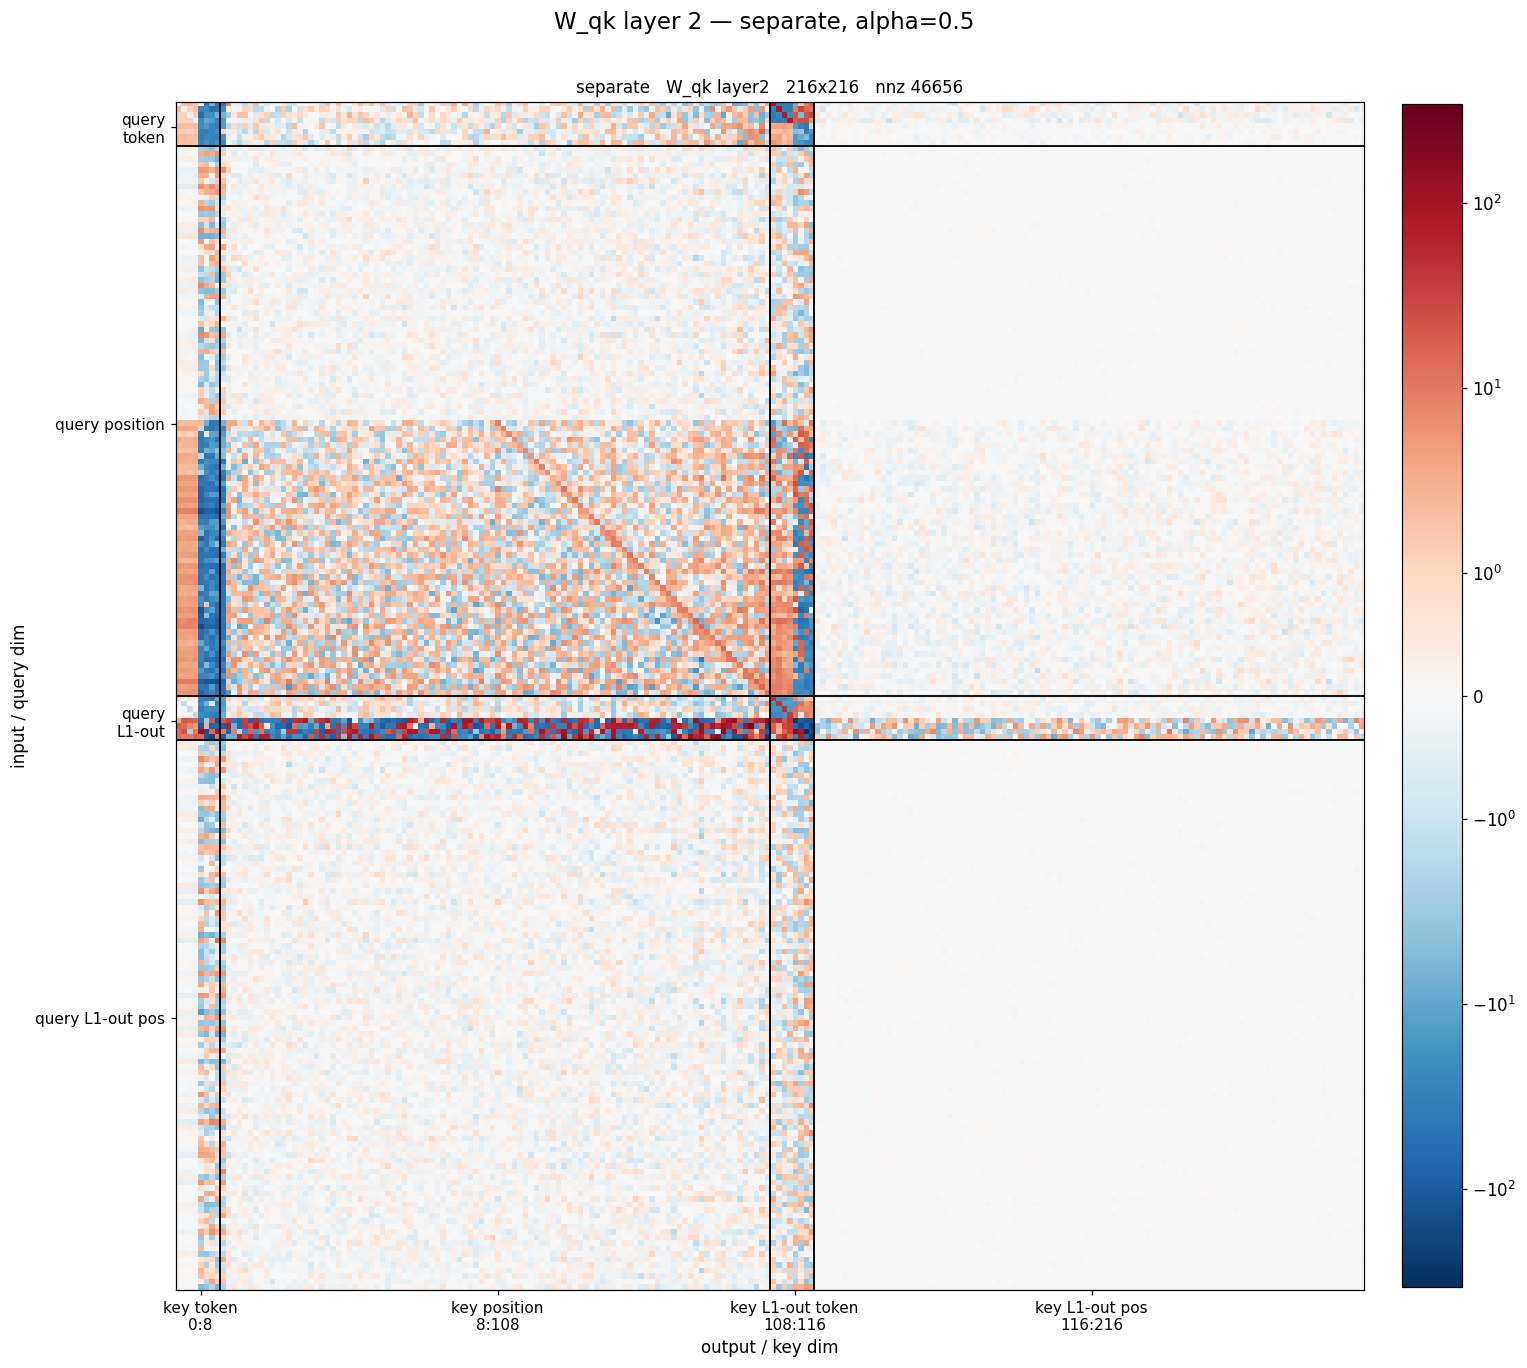

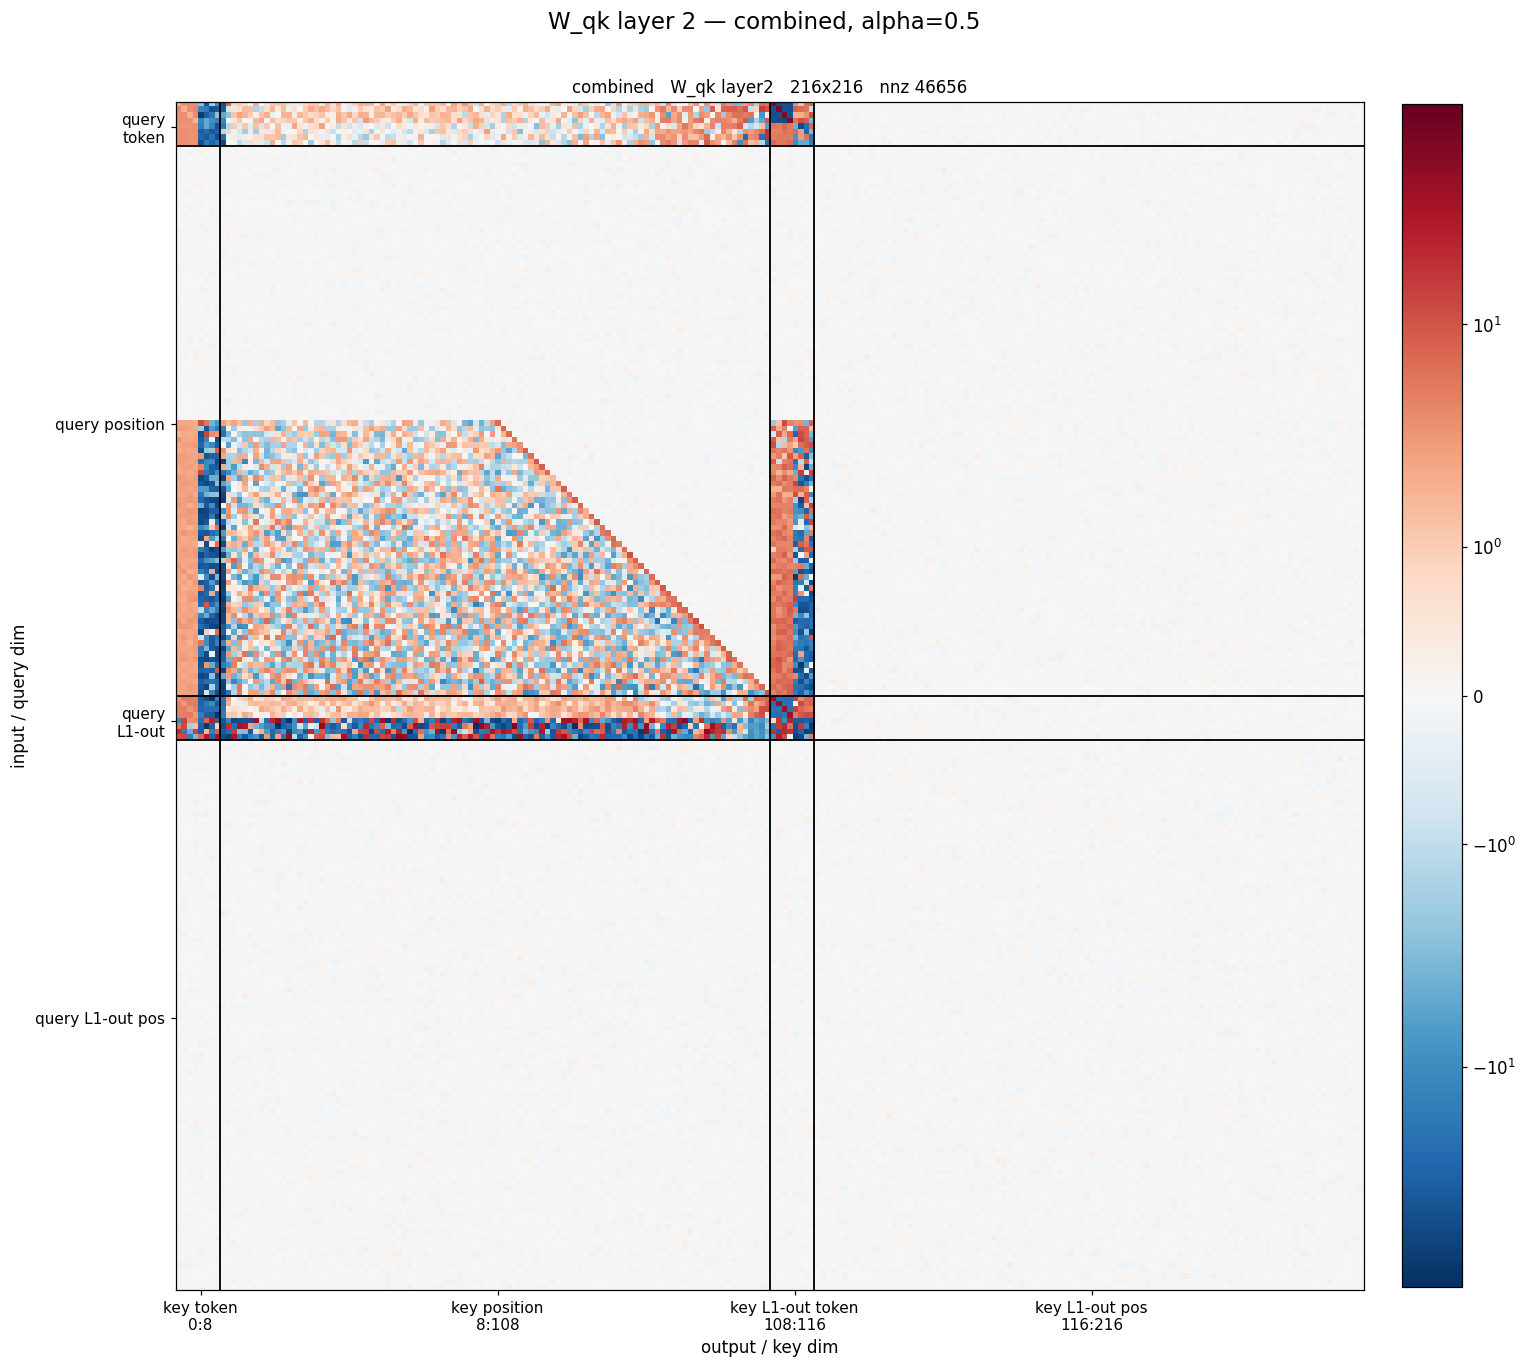

In [21]:
for nm, M in [('construction', PROD['W_qk layer2'])] + [(a, QKL[a][1]) for a in ARCHS]:
    fig, ax = plt.subplots(figsize=(14, 13))
    im = show(ax, M, f'{nm}   W_qk layer2', lw=1.2)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    ax.set_xticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_xticklabels(['key token\n0:8', 'key position\n8:108',
                        'key L1-out token\n108:116', 'key L1-out pos\n116:216'], fontsize=10)
    ax.set_yticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_yticklabels(['query\ntoken', 'query position', 'query\nL1-out', 'query L1-out pos'],
                       fontsize=10)
    fig.suptitle(f'W_qk layer 2 — {nm}, alpha={THR}', fontsize=15)
    fig.tight_layout()
    fig.savefig(os.path.join(ART, f'learned_wqk2_{nm}_a{THR}.png'), bbox_inches='tight')
    plt.show()

## 7.4 The same four close-ups, side by side

Every cell value printed, exactly as in section 5 — construction in the left column.

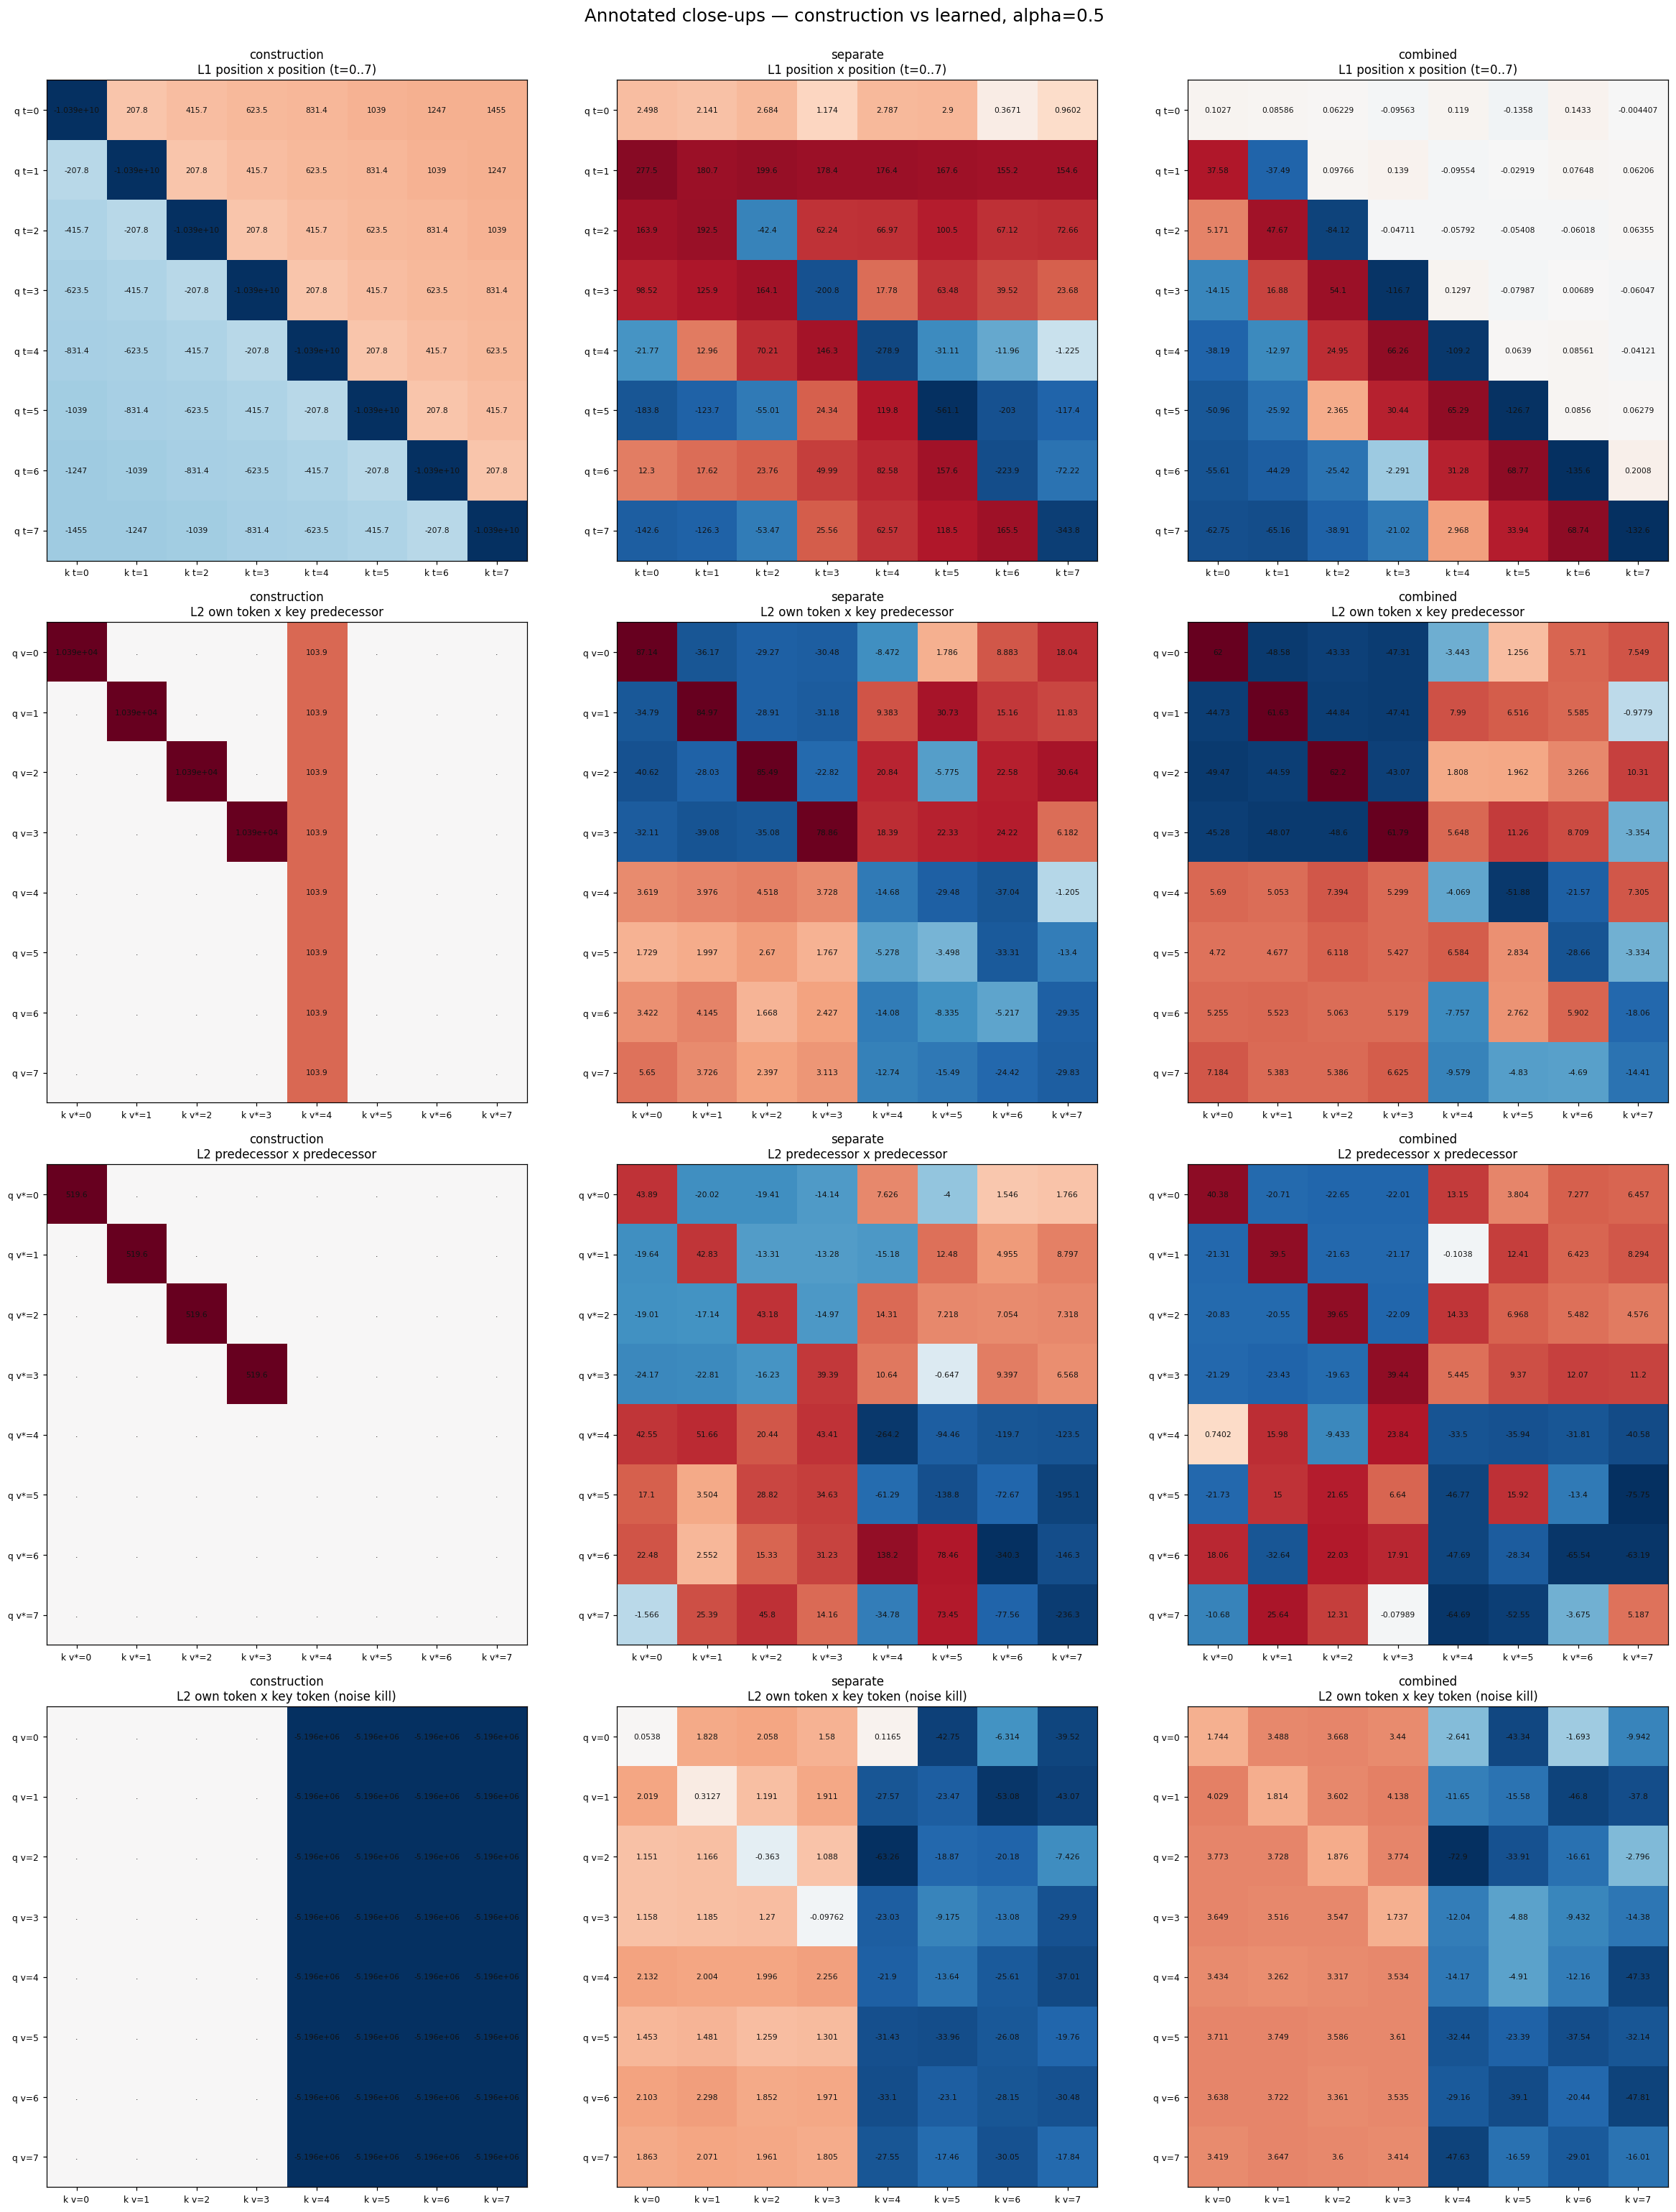

In [22]:
BLOCKS = [('L1 position x position (t=0..7)', 'W_qk layer1', 0, V, V + 8, V, V + 8,
           [f'q t={i}' for i in range(8)], [f'k t={i}' for i in range(8)]),
          ('L2 own token x key predecessor', 'W_qk layer2', 1, 0, V, D, D + V,
           [f'q v={i}' for i in range(V)], [f'k v*={i}' for i in range(V)]),
          ('L2 predecessor x predecessor', 'W_qk layer2', 1, D, D + V, D, D + V,
           [f'q v*={i}' for i in range(V)], [f'k v*={i}' for i in range(V)]),
          ('L2 own token x key token (noise kill)', 'W_qk layer2', 1, 0, V, 0, V,
           [f'q v={i}' for i in range(V)], [f'k v={i}' for i in range(V)])]

fig, axes = plt.subplots(len(BLOCKS), 3, figsize=(22, 7.0 * len(BLOCKS)))
for r, (title, key, li, r0, r1, c0, c1, rlab, clab) in enumerate(BLOCKS):
    for c, (nm, M) in enumerate([('construction', PROD[key])] +
                                [(a, QKL[a][li]) for a in ARCHS]):
        annot(axes[r][c], M, r0, r1, c0, c1, f'{nm}\n{title}', rlab=rlab, clab=clab, fs=7)
fig.suptitle(f'Annotated close-ups — construction vs learned, alpha={THR}', fontsize=16, y=0.999)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'learned_closeups_a{THR}.png'), bbox_inches='tight')
plt.show()

## 7.5 How the key block changes with $\alpha$

The layer-2 own-token x predecessor block — the induction match — across all seven thresholds.
This is the block whose diagonal must dominate for the head to work.

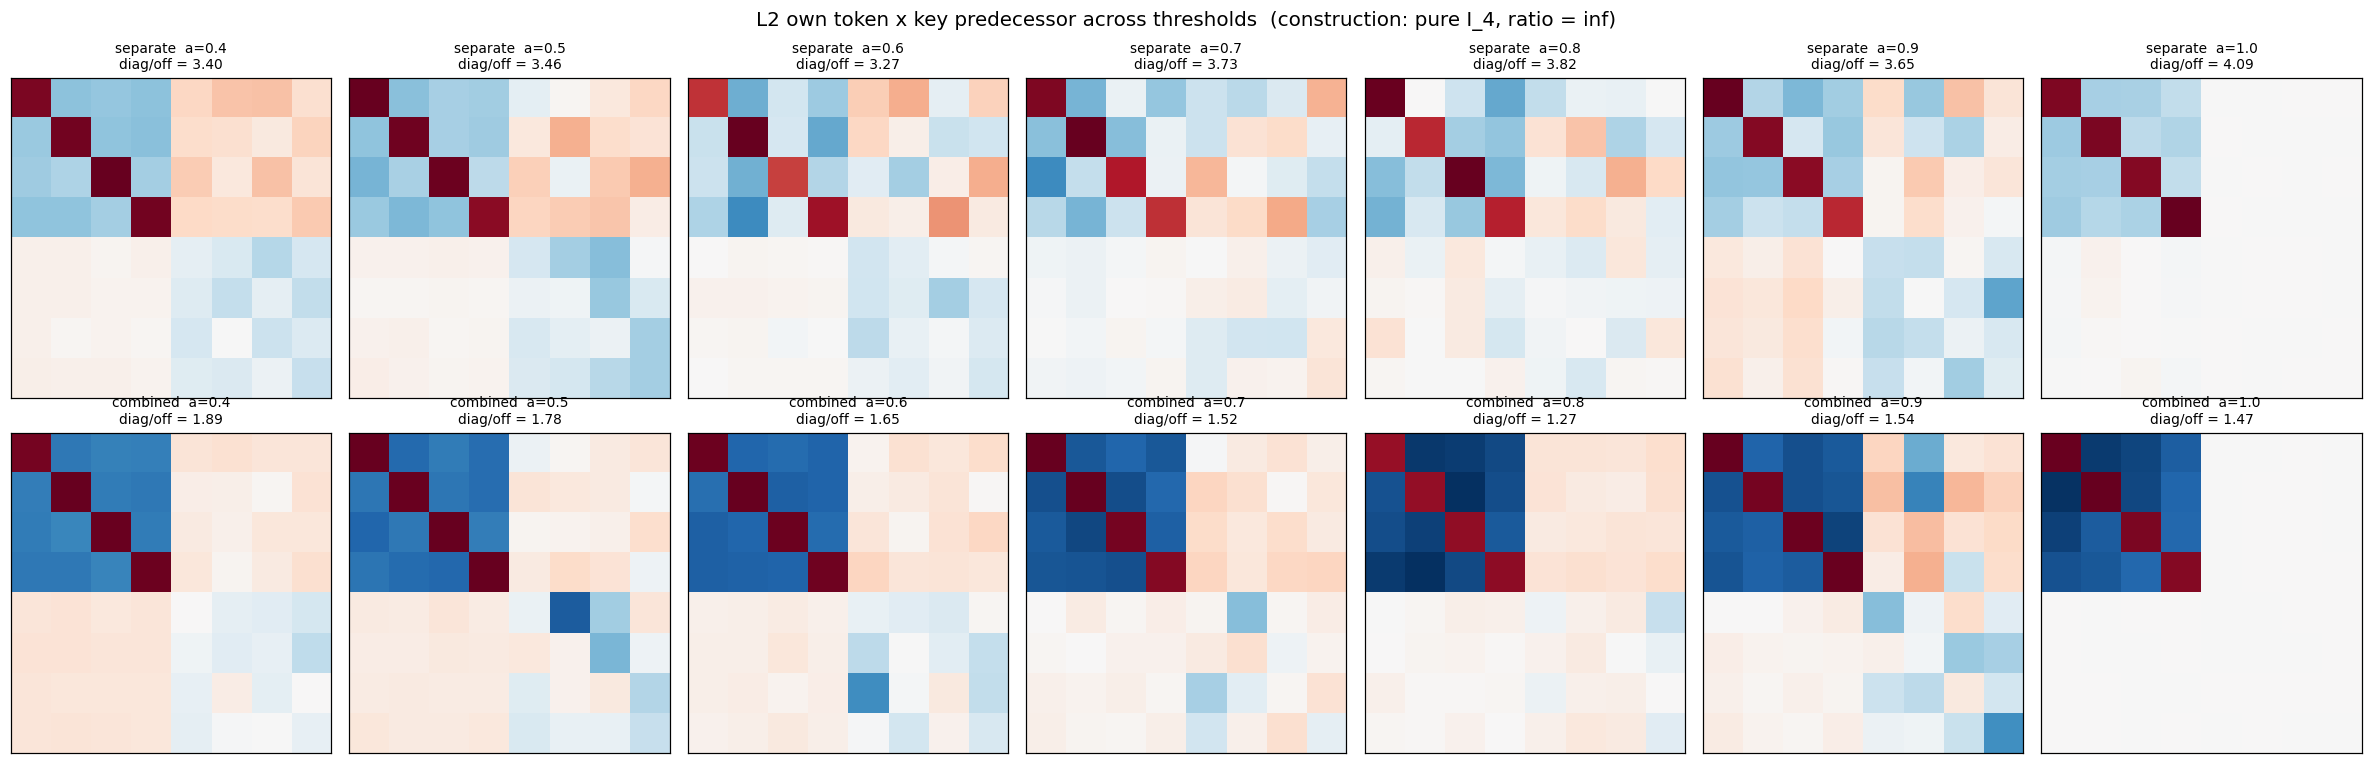

In [23]:
ALL_THRS = sorted(float(p.split('_x_')[1][:-4])
                  for p in glob.glob(os.path.join(CDIR, 'model_separate_*.pth')))
fig, axes = plt.subplots(2, len(ALL_THRS), figsize=(3.1 * len(ALL_THRS), 7.2))
for j, t in enumerate(ALL_THRS):
    for i, a in enumerate(ARCHS):
        M = eff(load(a, t))[0][1]
        b = M[:V, D:D + V].numpy()
        v = np.abs(b).max() or 1.0
        axes[i][j].imshow(b, cmap='RdBu_r', vmin=-v, vmax=v, interpolation='nearest')
        dg = np.abs(np.diag(b[:VS, :VS])).mean()
        of = np.abs(b[:VS, :VS] - np.diag(np.diag(b[:VS, :VS]))).mean()
        axes[i][j].set_title(f'{a}  a={t}\ndiag/off = {dg/max(of,1e-30):.2f}', fontsize=9)
        axes[i][j].set_xticks([]); axes[i][j].set_yticks([])
fig.suptitle('L2 own token x key predecessor across thresholds  (construction: pure I_4, ratio = inf)',
             fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'learned_l2_block_all_thresholds.png'), bbox_inches='tight')
plt.show()

## 7.6 What to take from this

Read the panels against section 6's target:

* **Amplitude.** The learned $\|W_{qk}\|_F$ is a tiny fraction of the construction's — the ratio is
  printed in the table at 7.0. GD never travels the eight orders of magnitude to the $-10^9$
  suppression terms, because it does not need to: only the softmax's *ordering* matters, and a
  low-amplitude pattern with the same ordering produces the same attention.
* **Density.** The construction is 0.10% non-zero in layer 2; the learned matrices are fully
  dense. What GD finds is the right structure *plus* a lot of small noise that the softmax
  ignores.
* **The blocks that matter.** In the close-ups, look at whether the 4x4 diagonal of the
  own-token x predecessor block stands out from its off-diagonal — that ratio is the induction
  match, and 7.5 tracks it across every threshold.
* $W_{ov}$ was frozen, so its panels are the construction by definition; they are shown only to
  confirm the freeze held.